<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 06: A single replicate of the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.5 and 6.6). Problem numbers follow the 8th edition.

## Learning goals

* Compute all $2^k - 1$ effects of an unreplicated $2^k$ design and explain why the full model has no error term.
* Identify the active effects with the normal (Daniel) and half-normal probability plots and with Lenth's method
  (pseudo standard error, margin of error, simultaneous margin of error, Pareto plot).
* Project the design onto the active factors, fit and check the final model and interpret it with contour plots.
* Recognize the effect of an outlier on the normal plot of effects.
* Use a transformation of the response (log, Box-Cox) and detect dispersion effects from the residuals.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercise 5).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `pareto_plot()` - bar chart of the absolute effects with the $ME$ and $SME$ lines.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.graphics.factorplots import interaction_plot

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def pareto_plot(effects, alpha=0.05, ax=None):
    """Bars of |effect| sorted by size with Lenth's ME and SME lines."""
    L = lenth(effects, alpha)
    e = effects.abs().sort_values(ascending=False)
    if ax is None:
        ax = plt.subplots(figsize=(9, 3.5))[1]
    ax.bar(e.index, e.to_numpy(), color=np.where(e > L["ME"], "tab:blue", "lightgray"))
    ax.axhline(L["ME"], color="tab:orange", ls="--", label=f"ME = {L['ME']:.2f}")
    ax.axhline(L["SME"], color="tab:red", ls="--", label=f"SME = {L['SME']:.2f}")
    ax.set_ylabel("|effect|")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    ax.set_title("Pareto plot of the effects (Lenth)")
    return ax


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.3 * (2 + len(factors)), 3.2))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: filtration rate ($2^4$ design, a single replicate)

Montgomery, Example 6.2: the filtration rate (gal/h) of a resin in a pilot plant. Four factors: $A$ temperature,
$B$ pressure, $C$ concentration of formaldehyde, $D$ stirring rate. One replicate of the $2^4$ design, the 16 runs in random
order. The aim is to **maximize** the filtration rate. The file lists the runs in standard order.

In [2]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
factors = list("ABCD")
rate["label"] = ["".join(f.lower() for f in factors if r[f] == 1) or "(1)" for _, r in rate.iterrows()]
rate

,A,B,C,D,Rate,label
0,-1,-1,-1,-1,45,(1)
1,1,-1,-1,-1,71,a
2,-1,1,-1,-1,48,b
3,1,1,-1,-1,65,ab
4,-1,-1,1,-1,68,c
5,1,-1,1,-1,60,ac
6,-1,1,1,-1,80,bc
7,1,1,1,-1,65,abc
8,-1,-1,-1,1,43,d
9,1,-1,-1,1,100,ad


### Main effects and interaction plots

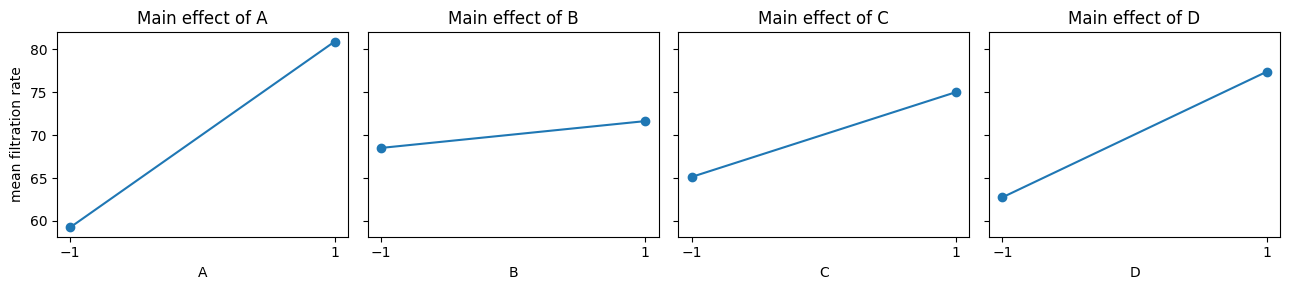

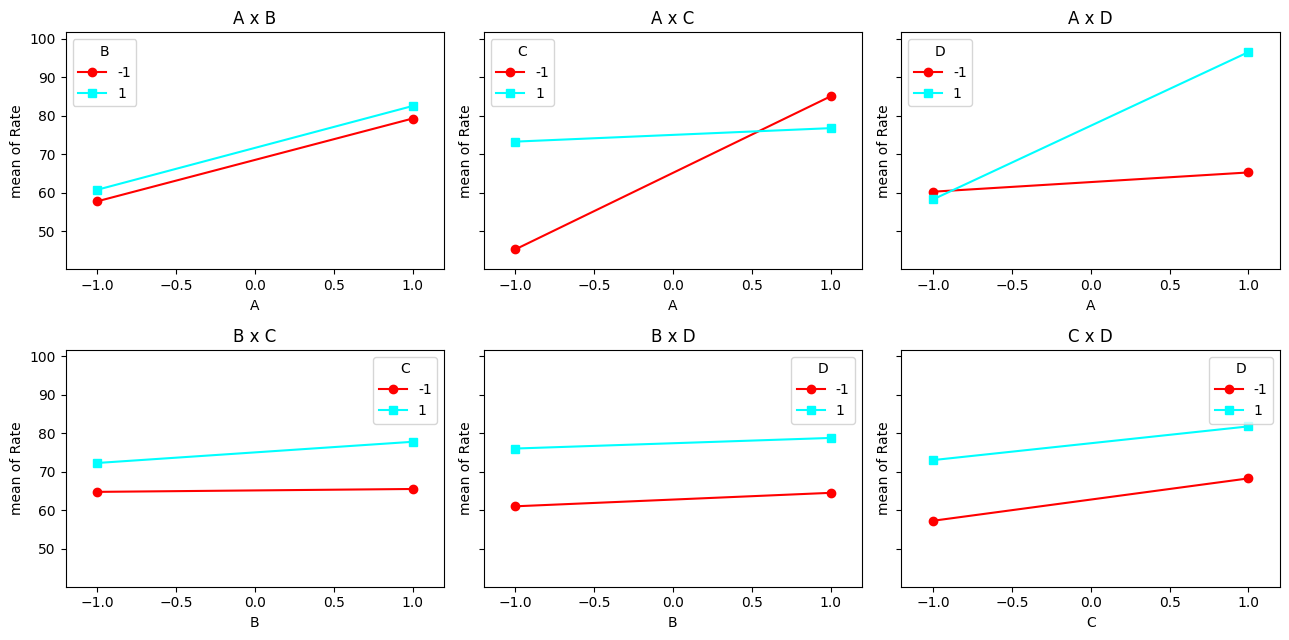

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, f in zip(axes, factors):
    m = rate.groupby(f)["Rate"].mean()
    ax.plot(m.index, m.to_numpy(), "o-")
    ax.set(xticks=[-1, 1], xlabel=f, title=f"Main effect of {f}")
axes[0].set_ylabel("mean filtration rate")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (f1, f2) in zip(axes.flat, itertools.combinations(factors, 2)):
    interaction_plot(rate[f1], rate[f2], rate["Rate"], ax=ax, markers=["o", "s"])
    ax.set_title(f"{f1} x {f2}")
plt.tight_layout()
plt.show()

The plots suggest large main effects of $A$, $C$, $D$ and interactions $A \times C$ and $A \times D$. The lines of $B$ are
almost flat. But without an error estimate we cannot say which differences are larger than the noise.

### The full model has no error term

In [4]:
import warnings

full = smf.ols("Rate ~ A*B*C*D", data=rate).fit()
print("residual degrees of freedom:", full.df_resid)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)     # division by the zero residual df
    print(anova_lm(full).round(2))

residual degrees of freedom: 0.0
           df   sum_sq  mean_sq    F  PR(>F)
A         1.0  1870.56  1870.56  0.0     NaN
B         1.0    39.06    39.06  0.0     NaN
A:B       1.0     0.06     0.06  0.0     NaN
C         1.0   390.06   390.06  0.0     NaN
A:C       1.0  1314.06  1314.06  0.0     NaN
B:C       1.0    22.56    22.56  0.0     NaN
A:B:C     1.0    14.06    14.06  0.0     NaN
D         1.0   855.56   855.56  0.0     NaN
A:D       1.0  1105.56  1105.56  0.0     NaN
B:D       1.0     0.56     0.56  0.0     NaN
A:B:D     1.0    68.06    68.06  0.0     NaN
C:D       1.0     5.06     5.06  0.0     NaN
A:C:D     1.0    10.56    10.56  0.0     NaN
B:C:D     1.0    27.56    27.56  0.0     NaN
A:B:C:D   1.0     7.56     7.56  0.0     NaN
Residual  0.0     0.00      inf  NaN     NaN


16 observations, 16 parameters, 0 residual degrees of freedom. The sums of squares are correct, but **statsmodels prints
$F = 0$ and missing $p$-values: these are not test results.** We have to judge the effects without an estimate of $\sigma^2$.

### Effects from the table of signs

In [5]:
eff_table = effects_2k(rate, "Rate", factors)
eff = eff_table["effect"].rename(lambda t: t.replace(":", ""))      # names A, B, AB, ..., ABCD
eff_table.round(3)

,contrast,effect,SS,coef
term,,,,
A,173,21.625,1870.562,10.812
B,25,3.125,39.062,1.562
A:B,1,0.125,0.062,0.062
C,79,9.875,390.062,4.938
A:C,-145,-18.125,1314.062,-9.062
B:C,19,2.375,22.562,1.188
A:B:C,15,1.875,14.062,0.938
D,117,14.625,855.562,7.312
A:D,133,16.625,1105.562,8.312


In [6]:
# the effects are twice the regression coefficients of the full model
check = 2 * full.params.drop("Intercept")
np.allclose(check[eff_table.index], eff_table["effect"])

True

### Normal and half-normal plots of the effects

A negligible effect is $N(0, 4\sigma^2/N)$; the negligible effects lie on a straight line, the active effects are outliers.

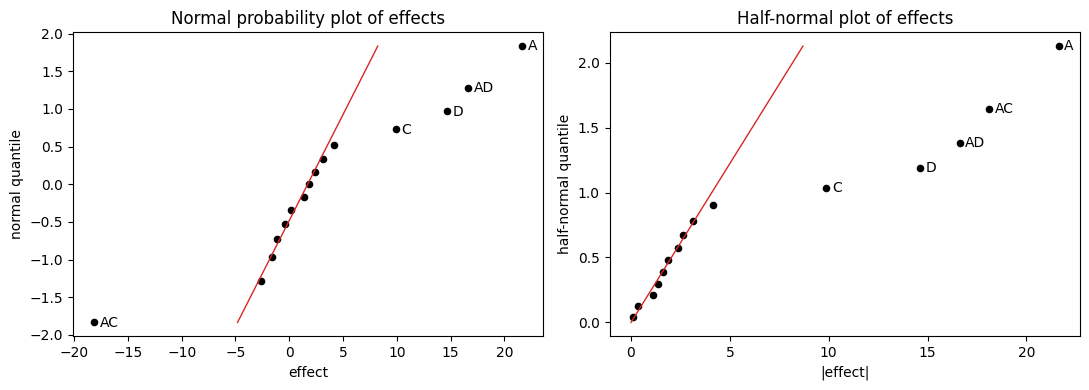

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0])
effect_plot(eff, half=True, ax=axes[1])
plt.tight_layout()
plt.show()

### Lenth's method and the Pareto plot

{'s0': np.float64(3.938), 'PSE': np.float64(2.625), 'ME': np.float64(6.748), 'SME': np.float64(13.699)}
|effect| > ME:  ['A', 'C', 'AC', 'D', 'AD']
|effect| > SME: ['A', 'AC', 'D', 'AD']


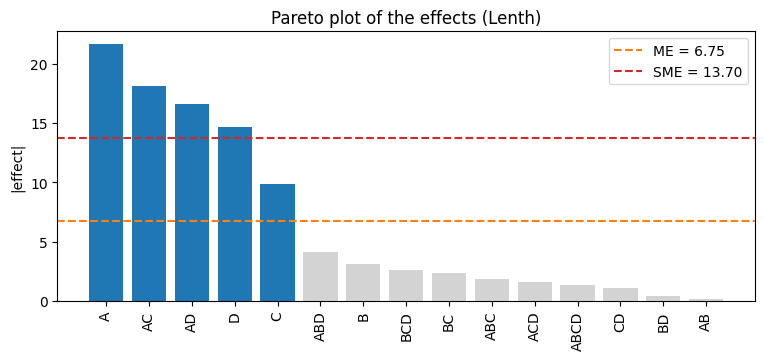

In [8]:
L = lenth(eff)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff[eff.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff[eff.abs() > L["SME"]].index))
pareto_plot(eff)
plt.show()

$PSE = 2.625$, $ME = 6.75$, $SME = 13.70$ (the same numbers as Montgomery). The effects $A$, $AC$, $AD$, $D$ exceed $SME$,
$C$ exceeds only $ME$. Because $AC$ is clearly active, we keep $C$ (hierarchy). The tentative model is
$A + C + D + AC + AD$; factor $B$ (pressure) does not appear at all.

### Projection into a replicated $2^3$ design

Dropping $B$ projects the single replicate of the $2^4$ into a $2^3$ design in $A$, $C$, $D$ with two replicates, so now
we have 8 degrees of freedom for pure error. (Last year's notebook built this design by stacking two copies of the $2^3$
table and pairing them with the observations in the wrong order. Fitting the model to the original data frame without $B$
avoids that mistake.)

In [9]:
m_acd = smf.ols("Rate ~ A*C*D", data=rate).fit()
anova_lm(m_acd)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,83.367688,0.000017
C,1.0,390.0625,390.0625,17.384401,0.003124
A:C,1.0,1314.0625,1314.0625,58.565460,0.000060
D,1.0,855.5625,855.5625,38.130919,0.000267
A:D,1.0,1105.5625,1105.5625,49.272981,0.000110
C:D,1.0,5.0625,5.0625,0.225627,0.647483
A:C:D,1.0,10.5625,10.5625,0.470752,0.512032
Residual,8.0,179.5000,22.4375,NaN,NaN


In [10]:
final = smf.ols("Rate ~ A + C + D + A:C + A:D", data=rate).fit()
print(anova_lm(final).round(4))
print(final.summary().tables[1])
print(f"s = {np.sqrt(final.scale):.3f}, R2 = {final.rsquared:.4f}, R2_adj = {final.rsquared_adj:.4f}")

            df     sum_sq    mean_sq        F  PR(>F)
A          1.0  1870.5625  1870.5625  95.8648  0.0000
C          1.0   390.0625   390.0625  19.9904  0.0012
D          1.0   855.5625   855.5625  43.8469  0.0001
A:C        1.0  1314.0625  1314.0625  67.3447  0.0000
A:D        1.0  1105.5625  1105.5625  56.6592  0.0000
Residual  10.0   195.1250    19.5125      NaN     NaN
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.0625      1.104     63.444      0.000      67.602      72.523
A             10.8125      1.104      9.791      0.000       8.352      13.273
C              4.9375      1.104      4.471      0.001       2.477       7.398
D              7.3125      1.104      6.622      0.000       4.852       9.773
A:C           -9.0625      1.104     -8.206      0.000     -11.523      -6.602
A:D            8.3125      1.104      7.527      0.000       5.852   

$$\hat y = 70.06 + 10.81\,x_1 + 4.94\,x_3 + 7.31\,x_4 - 9.06\,x_1x_3 + 8.31\,x_1x_4,$$
with $\hat\sigma = 4.42$ and $R^2 = 0.966$. The residual mean square 19.51 (10 df) is the pure error (8 df) plus the dropped
$CD$ and $ACD$ (2 df). Check the residuals, also against the dropped factor $B$:

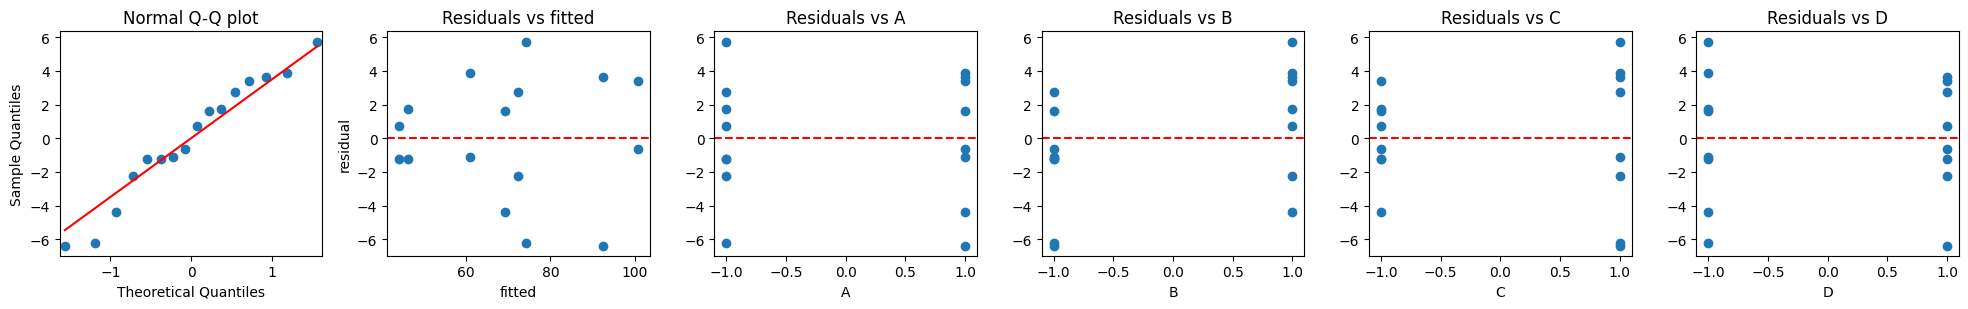

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9534713000836798), pvalue=np.float64(0.5465944384429886))


In [11]:
residual_plots(final, rate, factors)

### Contour plots and the best settings

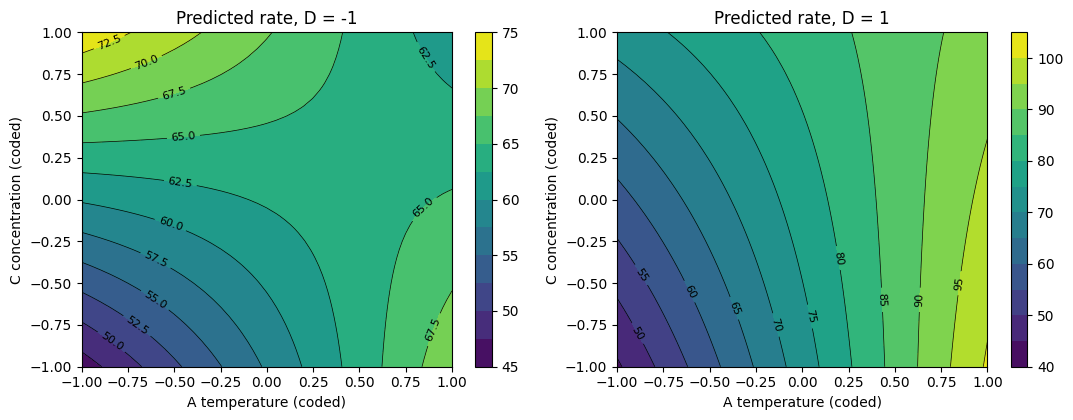

,A,C,D,predicted
5,1,-1,1,100.625
7,1,1,1,92.375
2,-1,1,-1,74.250


In [12]:
g = np.linspace(-1, 1, 41)
A, C = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "C": C.ravel(), "D": d})
    Z = final.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, C, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, C, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature (coded)", ylabel="C concentration (coded)", title=f"Predicted rate, D = {d}")
plt.tight_layout()
plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = final.predict(corners)
corners.sort_values("predicted", ascending=False).head(3)

The highest predicted filtration rate (100.6 gal/h) is at high temperature, low concentration of formaldehyde and high
stirring rate ($A = +$, $C = -$, $D = +$); pressure ($B$) can be set at the cheaper level. The model is linear with
interactions and should not be extrapolated outside the cube.

### Pooling only the highest-order interaction?

In [13]:
m_3way = smf.ols("Rate ~ (A + B + C + D)**3", data=rate).fit()
anova_lm(m_3way).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,247.3471,0.0404
B,1.0,39.0625,39.0625,5.1653,0.2639
C,1.0,390.0625,390.0625,51.5785,0.0881
D,1.0,855.5625,855.5625,113.1322,0.0597
A:B,1.0,0.0625,0.0625,0.0083,0.9423
A:C,1.0,1314.0625,1314.0625,173.7603,0.0482
A:D,1.0,1105.5625,1105.5625,146.1901,0.0525
B:C,1.0,22.5625,22.5625,2.9835,0.3341
B:D,1.0,0.5625,0.5625,0.0744,0.8305
C:D,1.0,5.0625,5.0625,0.6694,0.5635


The error term is $ABCD$ with **one** degree of freedom, $F_{0.05,1,1} = 161.4$: even the large effects $C$, $D$ and
$AD$ are not significant. Such a test has almost no power; the normal plot / Lenth's method and the projection are better.

### The effect of an outlier

Suppose the run $cd$ was recorded as 375 instead of 75 (Montgomery, Section 6.5). The error of 300 enters every effect with
weight $\pm 300/8 = \pm 37.5$.

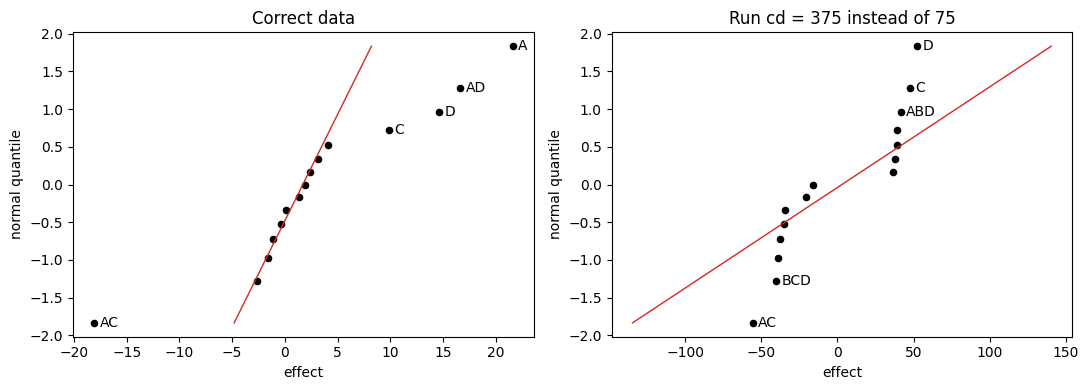

Lenth with the outlier: {'s0': np.float64(58.31), 'PSE': np.float64(58.31), 'ME': np.float64(149.9), 'SME': np.float64(304.31)}


In [14]:
bad = rate.copy()
bad.loc[bad["label"] == "cd", "Rate"] = 375
eff_bad = effects_2k(bad, "Rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0], title="Correct data")
effect_plot(eff_bad, ax=axes[1], title="Run cd = 375 instead of 75")
plt.tight_layout()
plt.show()
print("Lenth with the outlier:", {k: round(v, 2) for k, v in lenth(eff_bad).items()})

The effects split into two groups around $\pm 37.5$ with a gap in the middle; there is no straight line through the small
effects and Lenth's method finds nothing. When the normal plot looks like this, check the data first.

----

## 2. Lecture example: data transformation (drill advance rate)

Montgomery, Example 6.3 (Daniel, 1976): a single replicate of a $2^4$ design for the advance rate of a drill. Factors: drill
load ($A$), flow rate ($B$), rotational speed ($C$) and type of drilling mud ($D$). The data are read from Figure 6.19 of the
book and entered in standard order.

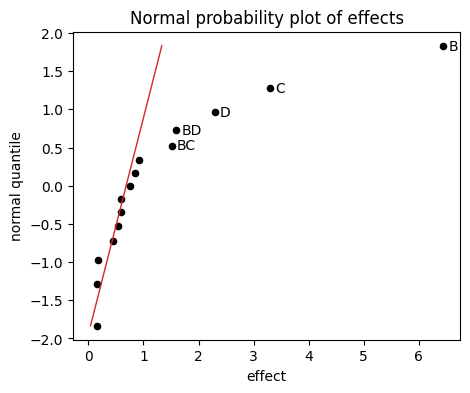

term
AC      0.155
ABC     0.163
BCD     0.175
CD      0.448
ABCD    0.543
ACD     0.585
AB      0.590
ABD     0.760
AD      0.838
A       0.918
BC      1.510
BD      1.592
D       2.290
C       3.293
B       6.438
Name: effect, dtype: float64

In [15]:
drill = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
drill["rate"] = [1.68, 1.98, 4.98, 5.70, 3.24, 3.44, 9.97, 9.07,
                 2.07, 2.44, 7.77, 9.43, 4.09, 4.53, 11.75, 16.30]
eff_drill = effects_2k(drill, "rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_drill)
plt.show()
eff_drill.sort_values().round(3)

On the original scale $B$, $C$, $D$ and the interactions $BC$, $BD$ look active. Fit this model and look at the residuals:

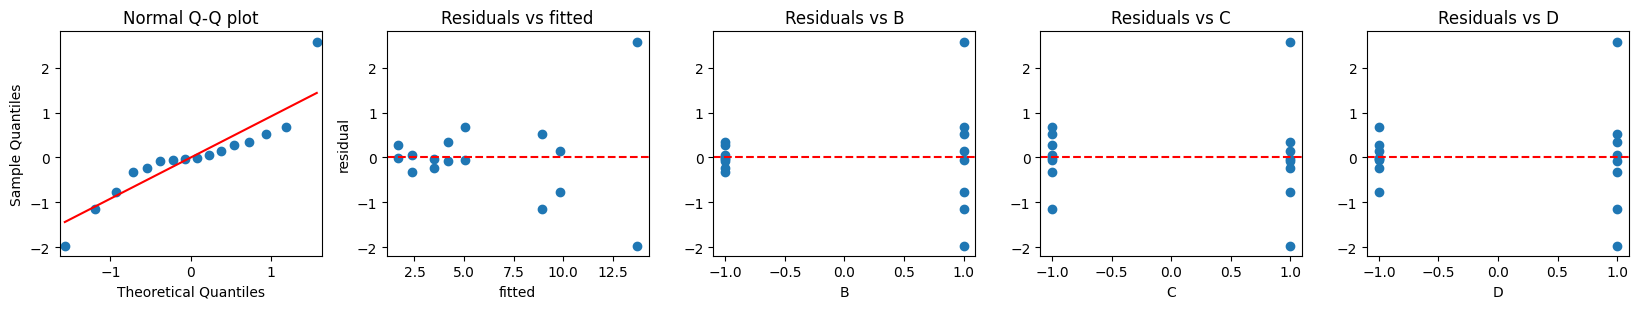

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8811859330110852), pvalue=np.float64(0.04049249370392257))


In [16]:
m_raw = smf.ols("rate ~ B + C + D + B:C + B:D", data=drill).fit()
residual_plots(m_raw, drill, ["B", "C", "D"])

The residuals form a **funnel**: their spread grows with the predicted advance rate. The response is a rate, the effects are
likely multiplicative, so try the log transformation. A quick Box-Cox check: residual sum of squares of the model $B + C + D$
for the scaled power transformation $y^{(\lambda)} = (y^\lambda - 1)/(\lambda \dot y^{\lambda - 1})$ ($\dot y$ = geometric
mean, $\lambda = 0$: $\dot y \ln y$), so that the values are comparable across $\lambda$.

In [17]:
gm = np.exp(np.log(drill["rate"]).mean())
for lam in [1, 0.5, 0, -0.5, -1]:
    if lam == 0:
        y_lam = gm * np.log(drill["rate"])
    else:
        y_lam = (drill["rate"]**lam - 1) / (lam * gm**(lam - 1))
    ssr = smf.ols("y ~ B + C + D", data=drill.assign(y=y_lam)).fit().ssr
    print(f"lambda = {lam:5.1f}: residual SS = {ssr:6.2f}")

lambda =   1.0: residual SS =  32.81
lambda =   0.5: residual SS =  10.55
lambda =   0.0: residual SS =   4.21
lambda =  -0.5: residual SS =   7.87
lambda =  -1.0: residual SS =  23.26


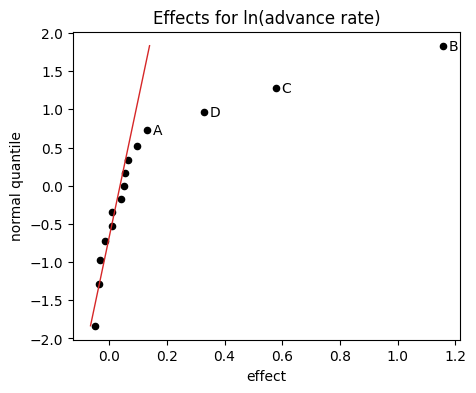

            df  sum_sq  mean_sq         F  PR(>F)
B          1.0  5.3452   5.3452  371.4928  0.0000
C          1.0  1.3389   1.3389   93.0517  0.0000
D          1.0  0.4305   0.4305   29.9224  0.0001
Residual  12.0  0.1727   0.0144       NaN     NaN
R2 = 0.9763


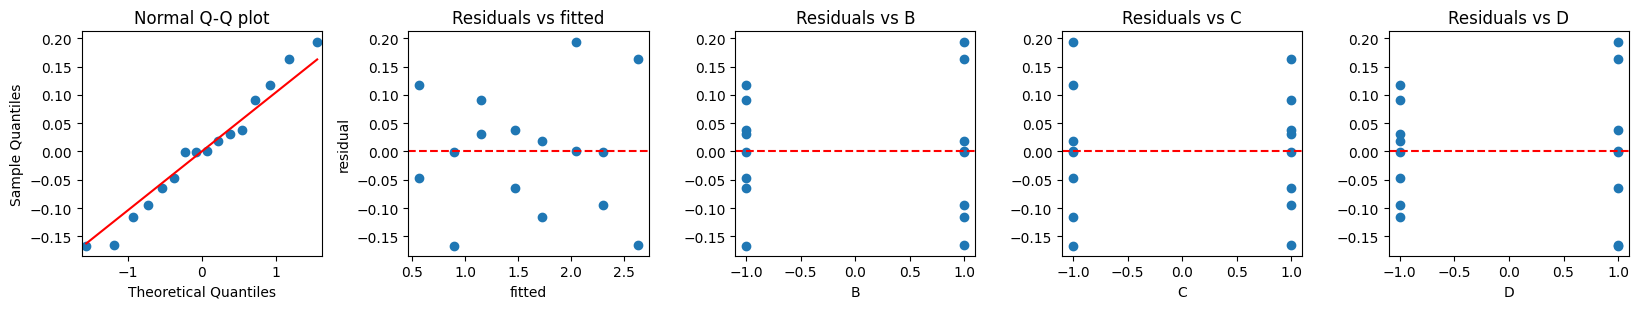

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9681448902399931), pvalue=np.float64(0.8077359505482492))


In [18]:
drill["log_rate"] = np.log(drill["rate"])
eff_log = effects_2k(drill, "log_rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_log, n_label=4, title="Effects for ln(advance rate)")
plt.show()

m_log = smf.ols("log_rate ~ B + C + D", data=drill).fit()
print(anova_lm(m_log).round(4))
print(f"R2 = {m_log.rsquared:.4f}")
residual_plots(m_log, drill, ["B", "C", "D"])

After the log transformation only the main effects $B$, $C$, $D$ are active, the interactions disappeared and the residuals
look fine ($R^2 = 0.976$). Predictions are computed on the log scale and transformed back with `np.exp` (this estimates
the median of the advance rate):

In [19]:
new = pd.DataFrame({"B": [1], "C": [1], "D": [1]})
print("predicted advance rate at B = C = D = +1:", np.exp(m_log.predict(new)).round(2).iloc[0])

predicted advance rate at B = C = D = +1: 13.85


----

## 3. Lecture example: location and dispersion effects (panel process)

Montgomery, Example 6.4: a single replicate of a $2^4$ design in a process producing interior panels for aircraft. Response:
the average number of defects per panel in a press load. Factors: temperature $A$ (295, 325 $^\circ$F), clamp time $B$
(7, 9 min), resin flow $C$ (10, 20), closing time $D$ (15, 30 s). Data from Figure 6.26 of the book, in standard order.

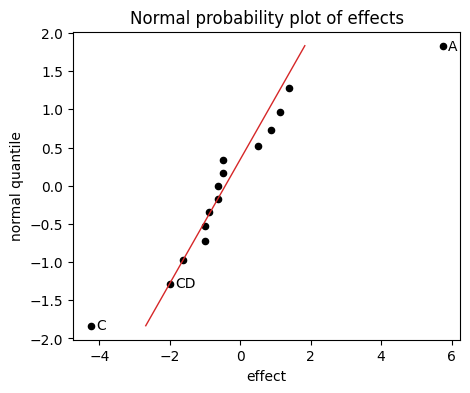

Intercept    6.688
A            2.875
C           -2.125
dtype: float64 R2 = 0.775


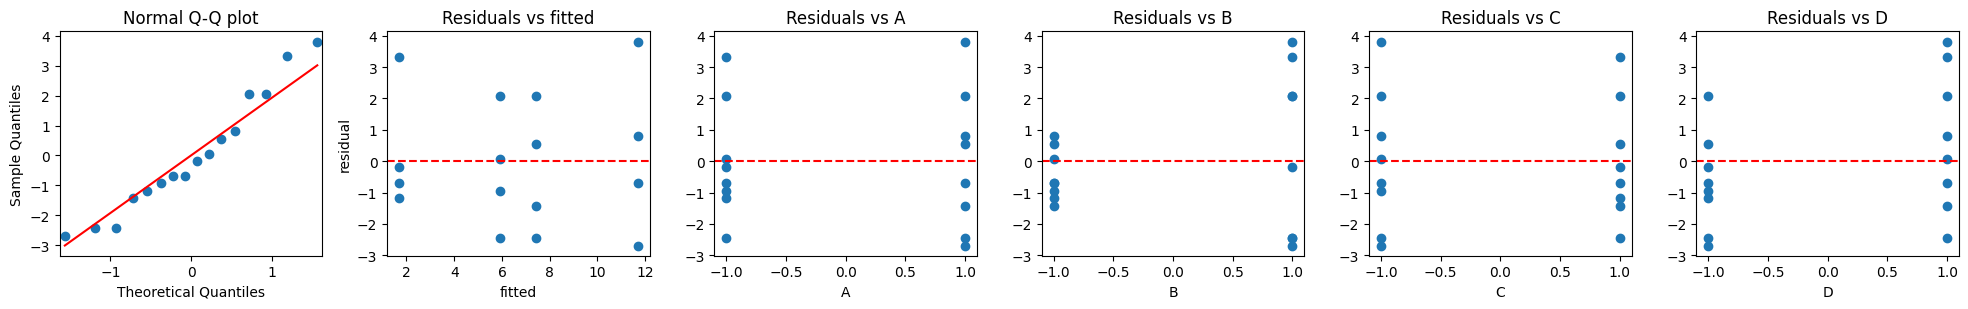

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9427968214827391), pvalue=np.float64(0.38469529327484786))


In [20]:
panel = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
panel["defects"] = [5, 11, 3.5, 9, 0.5, 8, 1.5, 9.5, 6, 12.5, 8, 15.5, 1, 6, 5, 5]
eff_panel = effects_2k(panel, "defects", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_panel, n_label=3)
plt.show()

m_loc = smf.ols("defects ~ A + C", data=panel).fit()
print(m_loc.params.round(3), f"R2 = {m_loc.rsquared:.3f}")
residual_plots(m_loc, panel, factors)

Location effects: $A = 5.75$ and $C = -4.25$, so low temperature and high resin flow reduce the number of defects. The plot
of the residuals against $B$ (clamp time) shows a much larger spread at the high level of $B$. For every column of the table
of signs we compute the **dispersion effect**
$$F_i^* = \ln \frac{S^2(i^+)}{S^2(i^-)},$$
where $S(i^\pm)$ is the standard deviation of the residuals at the runs where the column is $\pm$.

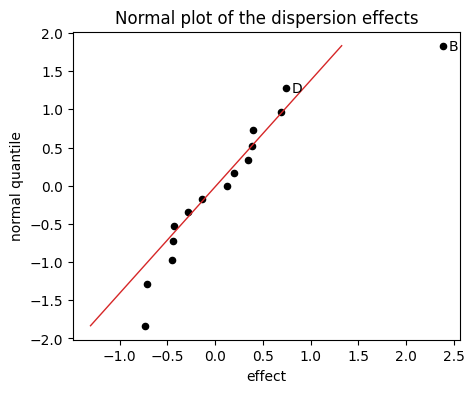

ABCD   -0.74
ACD    -0.71
BC     -0.45
ABC    -0.44
AC     -0.43
C      -0.29
ABD    -0.14
AD      0.13
BCD     0.20
AB      0.35
A       0.39
CD      0.40
BD      0.69
D       0.74
B       2.39
dtype: float64

In [21]:
e = m_loc.resid
Fstar = {}
for t in eff_panel.index:
    s = panel[list(t)].prod(axis=1)
    Fstar[t] = np.log(e[s == 1].var() / e[s == -1].var())
Fstar = pd.Series(Fstar)
effect_plot(Fstar, n_label=2, title="Normal plot of the dispersion effects")
plt.show()
Fstar.sort_values().round(2)

$F_B^* = 2.39$ stands out: clamp time does not change the mean number of defects, but the low clamp time gives a smaller
variability. Recommended: low temperature and high resin flow (location), low clamp time (dispersion).

----

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.17, 6.28 with 6.29,
  6.31 with 6.32 and 6.36**; Problem 6.30 is optional.
* Use the normal (or half-normal) plot of the effects together with Lenth's method to choose the model, respect the
  hierarchy, state the hypotheses, the test statistic, its $p$-value and your decision for the final model, check the
  residuals and end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex06_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 8 November 2026** (the next lecture is on
  9 November; Team Project 1 has the same deadline).

### Problem 6.17

An experimenter has run a single replicate of a $2^4$ design. The following effect estimates have been calculated:

| Effect | Estimate | Effect | Estimate | Effect | Estimate |
|---|---|---|---|---|---|
| $A$ | 76.95 | $AB$ | $-51.32$ | $ABC$ | $-2.82$ |
| $B$ | $-67.52$ | $AC$ | 11.69 | $ABD$ | $-6.50$ |
| $C$ | $-7.84$ | $AD$ | 9.78 | $ACD$ | 10.20 |
| $D$ | $-18.73$ | $BC$ | 20.78 | $BCD$ | $-7.98$ |
| | | $BD$ | 14.74 | $ABCD$ | $-6.25$ |
| | | $CD$ | 1.27 | | |

(a) Construct a normal probability plot of these effects.

(b) Identify a tentative model, based on the plot of the effects in part (a).

(c) (Added.) Apply Lenth's method. Does it lead to the same model?

**Solution:**

**(a) Normal probability plot of the effects.** The problem gives only the 15 effect estimates (no raw data). The same 15 numbers are stored in the
course data file `Data Sets for Homework Exercises.xls`, sheet *Chapter 06*, block *Problem 17*; the cell checks that they agree.

effects in the data file equal the table: True
effects sorted by size:
A       76.95
B      -67.52
AB     -51.32
BC      20.78
D      -18.73
BD      14.74
AC      11.69
ACD     10.20
AD       9.78
BCD     -7.98
C       -7.84
ABD     -6.50
ABCD    -6.25
ABC     -2.82
CD       1.27


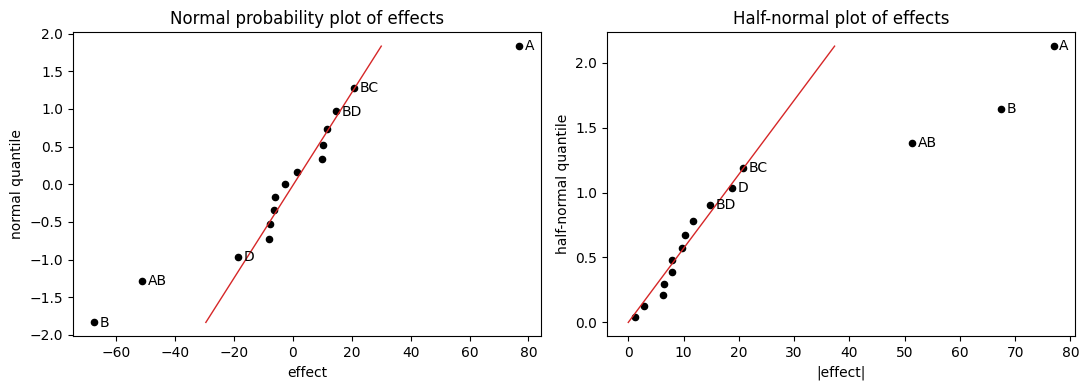

In [22]:
eff17 = pd.Series({"A": 76.95, "B": -67.52, "C": -7.84, "D": -18.73,
                   "AB": -51.32, "AC": 11.69, "AD": 9.78, "BC": 20.78, "BD": 14.74, "CD": 1.27,
                   "ABC": -2.82, "ABD": -6.50, "ACD": 10.20, "BCD": -7.98, "ABCD": -6.25})
try:
    xls = pd.read_excel(URL + "Data%20Sets%20for%20Homework%20Exercises.xls", sheet_name="Chapter 06", header=None)
    from_file = xls.iloc[3:18, 51:53].set_index(51)[52].astype(float)
    print("effects in the data file equal the table:", np.allclose(from_file.reindex(eff17.index), eff17))
except Exception as e:
    print("data file not read (needs the xlrd package):", e)

print("effects sorted by size:")
print(eff17.reindex(eff17.abs().sort_values(ascending=False).index).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff17, ax=axes[0], n_label=6)
effect_plot(eff17, half=True, ax=axes[1], n_label=6)
plt.tight_layout()
plt.show()

**(a), (b)** In the normal plot the twelve smallest effects ($|\text{effect}| \le 20.8$) lie on a straight line through zero: they behave like
a sample of noise. Three effects are far from the line: $A = 76.95$, $B = -67.52$ and $AB = -51.32$. $BC = 20.78$ and $D = -18.73$ sit at the
two ends of the line, not away from it, so we treat them as noise. The half-normal plot shows the same three points apart.

**Tentative model:** $A$, $B$ and $AB$,
$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_{12}\,x_1 x_2 + \varepsilon, \qquad \hat\beta_1 = 38.5,\ \hat\beta_2 = -33.8,\ \hat\beta_{12} = -25.7$$
(coefficient $=$ effect$/2$; the intercept is the grand mean, which is not given). The model is hierarchical: both main effects of the interaction are in it.

{'s0': np.float64(15.3), 'PSE': np.float64(13.32), 'ME': np.float64(34.24), 'SME': np.float64(69.51)}

effect / PSE (compare with t_0.025,5 = 2.571 for ME and 5.219 for SME):
A       5.78
B      -5.07
AB     -3.85
BC      1.56
D      -1.41
BD      1.11
AC      0.88
ACD     0.77
AD      0.73
BCD    -0.60
C      -0.59
ABD    -0.49
ABCD   -0.47
ABC    -0.21
CD      0.10

|effect| > ME:  ['A', 'B', 'AB']
|effect| > SME: ['A']
adjusted limits for m = 15 (Larntz and Whitcomb): ME = 28.50, SME = 55.45


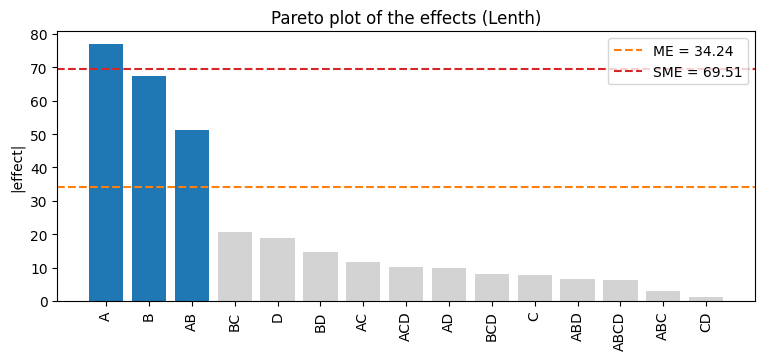

In [23]:
# (c) Lenth's method
L = lenth(eff17)
print({k: round(v, 2) for k, v in L.items()})
print("\neffect / PSE (compare with t_0.025,5 = 2.571 for ME and 5.219 for SME):")
print((eff17 / L["PSE"]).reindex(eff17.abs().sort_values(ascending=False).index).round(2).to_string())
print("\n|effect| > ME: ", list(eff17[eff17.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff17[eff17.abs() > L["SME"]].index))
print(f"adjusted limits for m = 15 (Larntz and Whitcomb): ME = {2.140 * L['PSE']:.2f}, SME = {4.163 * L['PSE']:.2f}")
pareto_plot(eff17)
plt.show()

**(c) Lenth's method.** $s_0 = 1.5 \cdot \text{median}|\text{effect}| = 15.3$; the effects below $2.5 s_0 = 38.3$ have median $8.88$, so
$PSE = 13.32$. With $d = 15/3 = 5$ df: $ME = 2.571 \cdot 13.32 = 34.2$ and $SME = 5.219 \cdot 13.32 = 69.5$.

$H_0$: the effect is zero, statistic effect$/PSE$: $A$: $5.78$, $B$: $-5.07$, $AB$: $-3.85$, then $BC$: $1.56$ and $D$: $-1.41$.
$A$, $B$ and $AB$ exceed $ME$ (rejected one by one), only $A$ exceeds the conservative $SME$. With the adjusted limits ($ME = 28.5$, $SME = 55.4$)
$A$ and $B$ exceed $SME$ and $AB$ exceeds $ME$. $BC$ and $D$ stay below every limit.

**Conclusion.** Lenth's method leads to the same model as the normal plot: $A$, $B$ and their interaction $AB$ are active, the other twelve effects
are noise. Fitting the model and checking its residuals would need the raw data.

### Problems 6.28 and 6.29: process development (yield)

In a process development study on yield, four factors were studied, each at two levels: time ($A$: 2.5 and 3 h),
concentration ($B$: 14 and 18 %), pressure ($C$: 60 and 80 psi) and temperature ($D$: 225 and 250 $^\circ$C). A single
replicate of a $2^4$ design was run. The file `Problem_6_28.csv` contains the factor levels in natural units and the
yield (lbs) in standard order (the actual run order is given in Table P6.7 of the book).

In [24]:
p628 = pd.read_csv(URL + "Problem_6_28.csv")
p628

,Time,Concentration,Pressure,Temperature,Yield
0,2.5,14,60,225,12
1,3.0,14,60,225,18
2,2.5,18,60,225,13
3,3.0,18,60,225,16
4,2.5,14,80,225,17
5,3.0,14,80,225,15
6,2.5,18,80,225,20
7,3.0,18,80,225,15
8,2.5,14,60,250,10
9,3.0,14,60,250,25


**Problem 6.28**

(a) Construct a normal probability plot of the effect estimates. Which factors appear to have large effects?

(b) Conduct an analysis of variance using the normal probability plot in part (a) for guidance in forming an error term.
What are your conclusions?

(c) Write down a regression model relating yield to the important process variables.

(d) Analyze the residuals from this experiment. Does your analysis indicate any potential problems?

(e) Can this design be collapsed into a $2^3$ design with two replicates? If so, sketch the design with the average and range
of yield shown at each point in the cube. Interpret the results.

Hint: first code the factors to $-1$/$+1$, for example `np.where(p628["Time"] == 3, 1, -1)`.

**Solution:**

**Coding.** $A$ time ($3$ h $= +1$), $B$ concentration ($18\ \% = +1$), $C$ pressure ($80$ psi $= +1$), $D$ temperature ($250\ ^\circ$C $= +1$).
A single replicate, so the full model has no error term; we start with the effects and their normal plot.

,contrast,effect,SS,coef
term,,,,
A,36,4.50,81.00,2.250
B,4,0.50,1.00,0.250
A:B,-6,-0.75,2.25,-0.375
C,16,2.00,16.00,1.000
A:C,-34,-4.25,72.25,-2.125
B:C,2,0.25,0.25,0.125
A:B:C,8,1.00,4.00,0.500
D,26,3.25,42.25,1.625
A:D,32,4.00,64.00,2.000


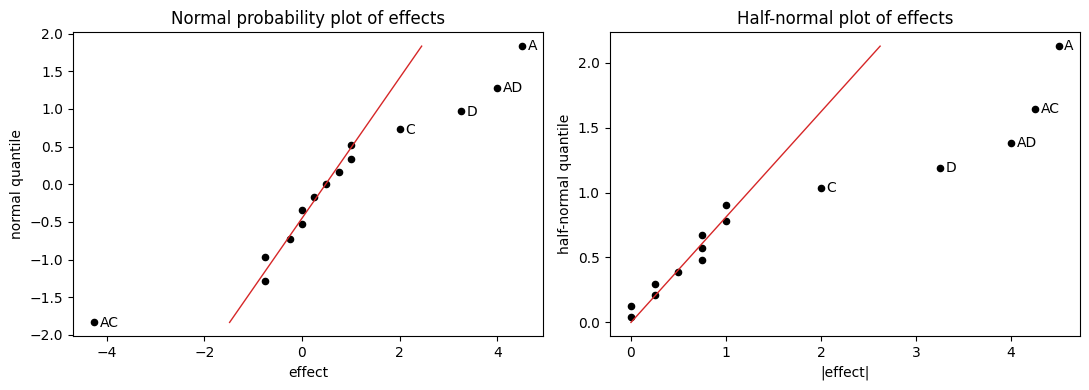

{'s0': np.float64(1.125), 'PSE': np.float64(1.125), 'ME': np.float64(2.892), 'SME': np.float64(5.871)}
|effect| > ME:  ['A', 'AC', 'D', 'AD']
|effect| > SME: []


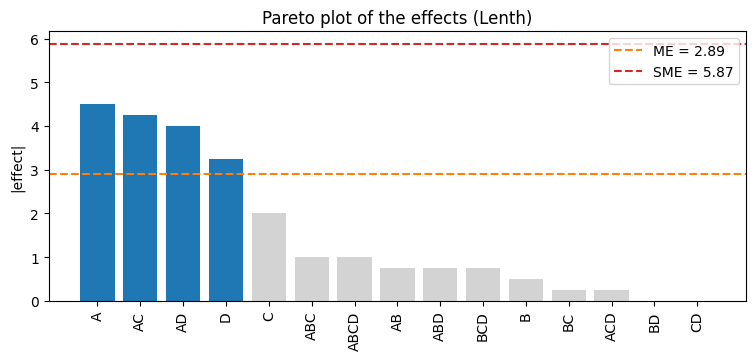

In [25]:
d628 = pd.DataFrame({"A": np.where(p628["Time"] == 3, 1, -1),
                     "B": np.where(p628["Concentration"] == 18, 1, -1),
                     "C": np.where(p628["Pressure"] == 80, 1, -1),
                     "D": np.where(p628["Temperature"] == 250, 1, -1),
                     "Yield": p628["Yield"]})
tab628 = effects_2k(d628, "Yield", list("ABCD"))
eff628 = tab628["effect"].rename(lambda t: t.replace(":", ""))
display(tab628.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff628, ax=axes[0], n_label=5)
effect_plot(eff628, half=True, ax=axes[1], n_label=5)
plt.tight_layout()
plt.show()
L = lenth(eff628)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff628[eff628.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff628[eff628.abs() > L["SME"]].index))
pareto_plot(eff628)
plt.show()

**(a)** Four effects leave the line: $A = 4.5$ (time), $AC = -4.25$ (time $\times$ pressure), $AD = 4.0$ (time $\times$ temperature) and
$D = 3.25$ (temperature). $C = 2.0$ (pressure) is at the edge of the line. Everything with $B$ (concentration) is close to zero
($B = 0.5$, $BD = CD = 0$). Lenth: $PSE = 1.125$, $ME = 2.89$, $SME = 5.87$; $A$, $AC$, $AD$ and $D$ exceed $ME$, none exceeds $SME$
(the active effects are only 3 to 4 times $PSE$). We keep $C$ because $AC$ is active (hierarchy).

**Tentative model:** $A$, $C$, $D$, $AC$, $AD$. Factor $B$ is not in it.

In [26]:
# (b) ANOVA: B is inactive, so the design projects into a 2^3 in A, C, D with two replicates (pure error with 8 df)
proj628 = smf.ols("Yield ~ A * C * D", data=d628).fit()
print("Projection A*C*D, pure error with 8 df:")
display(anova_lm(proj628).round(4))
m628 = smf.ols("Yield ~ A + C + D + A:C + A:D", data=d628).fit()
print("Final model, error = pure error + the dropped CD and ACD:")
display(anova_lm(m628).round(4))
print(f"MS_E = {m628.mse_resid:.3f} with {m628.df_resid:.0f} df, s = {np.sqrt(m628.scale):.3f}, "
      f"R2 = {m628.rsquared:.3f}, adj. R2 = {m628.rsquared_adj:.3f}")

Projection A*C*D, pure error with 8 df:


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,81.00,81.00,40.500,0.0002
C,1.0,16.00,16.00,8.000,0.0222
A:C,1.0,72.25,72.25,36.125,0.0003
D,1.0,42.25,42.25,21.125,0.0018
A:D,1.0,64.00,64.00,32.000,0.0005
C:D,1.0,0.00,0.00,0.000,1.0000
A:C:D,1.0,0.25,0.25,0.125,0.7328
Residual,8.0,16.00,2.00,NaN,NaN


Final model, error = pure error + the dropped CD and ACD:


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,81.00,81.000,49.8462,0.0000
C,1.0,16.00,16.000,9.8462,0.0105
D,1.0,42.25,42.250,26.0000,0.0005
A:C,1.0,72.25,72.250,44.4615,0.0001
A:D,1.0,64.00,64.000,39.3846,0.0001
Residual,10.0,16.25,1.625,NaN,NaN


MS_E = 1.625 with 10 df, s = 1.275, R2 = 0.944, adj. R2 = 0.916


**(b) ANOVA.** The error term is formed from the effects that the normal plot called noise. In the projection $A * C * D$ the error is the
pure error from the 8 pairs of runs ($MS_E = 2.0$, 8 df); the final model pools also $CD$ and $ACD$ ($SS = 0.25$) into it ($MS_E = 1.63$, 10 df).

$H_0$: the effect is zero, $F$-tests with $(1, 10)$ df. $A$: $F_0 = 49.8$, $P < 0.0001$. $AC$: $F_0 = 44.5$, $P = 0.0001$.
$AD$: $F_0 = 39.4$, $P = 0.0001$. $D$: $F_0 = 26.0$, $P = 0.0005$. $C$: $F_0 = 9.8$, $P = 0.011$. All five are **rejected** at $\alpha = 0.05$.
In the projection $CD$ ($P = 1.0$) and $ACD$ ($P = 0.73$) are not significant, which supports pooling them.

**Conclusions.** Time, pressure and temperature affect the yield, and the effects of pressure and of temperature depend on the time
(interactions $AC$, $AD$). Concentration has no effect in the range 14 to 18 %.

In [27]:
# (c) regression model in coded variables
print(m628.params.round(4).to_string())

Intercept    17.375
A             2.250
C             1.000
D             1.625
A:C          -2.125
A:D           2.000


**(c)** With $x_1$ = time, $x_3$ = pressure, $x_4$ = temperature (coded $\pm 1$):
$$\hat y = 17.375 + 2.25\,x_1 + 1.0\,x_3 + 1.625\,x_4 - 2.125\,x_1 x_3 + 2.0\,x_1 x_4 \quad \text{(lbs)}.$$
The coefficients are half of the effects. $R^2 = 0.944$, $s = 1.27$ lb.

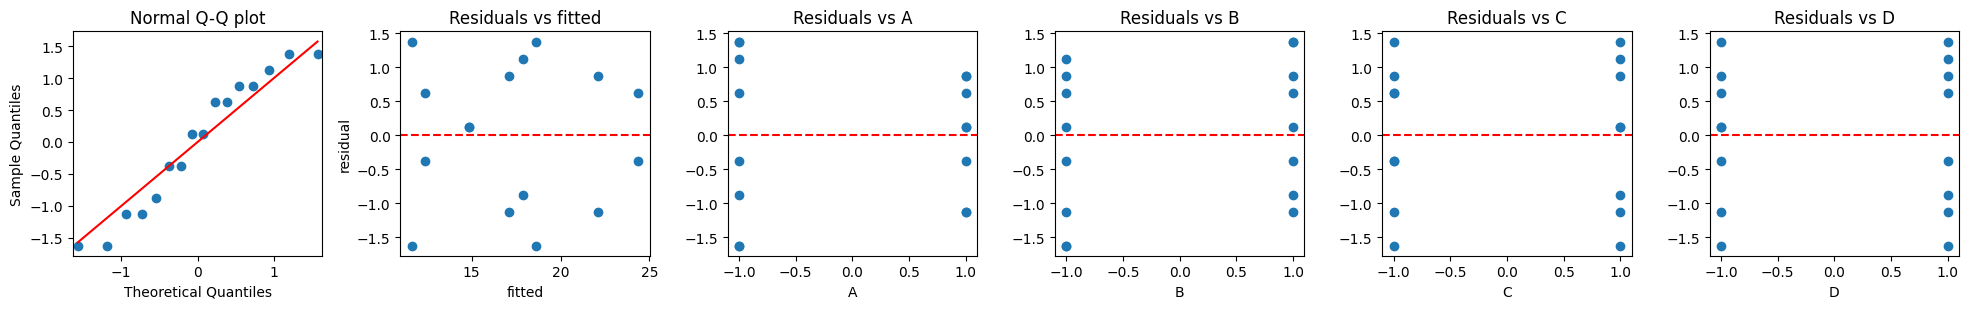

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9226963060387268), pvalue=np.float64(0.18638769990749662))
largest |standardized residual|: 1.61


In [28]:
# (d) residuals, also against the dropped factor B
residual_plots(m628, d628, list("ABCD"))
print("largest |standardized residual|:", np.abs(m628.get_influence().resid_studentized_internal).max().round(2))

**(d)** The Q-Q plot is roughly a straight line (Shapiro-Wilk $p = 0.19$); its steps come from the yield being recorded in whole pounds, so the
residuals take only a few distinct values. Residuals versus fitted values show no funnel, and there is no pattern against any factor, including
the dropped $B$. The largest standardized residual is $1.6$. No problems.

,A,C,D,mean,range,runs
0,-1,-1,-1,12.5,1,"[12, 13]"
1,-1,-1,1,11.5,3,"[10, 13]"
2,-1,1,-1,18.5,3,"[17, 20]"
3,-1,1,1,18.0,2,"[19, 17]"
4,1,-1,-1,17.0,2,"[18, 16]"
5,1,-1,1,24.5,1,"[25, 24]"
6,1,1,-1,15.0,0,"[15, 15]"
7,1,1,1,22.0,2,"[21, 23]"


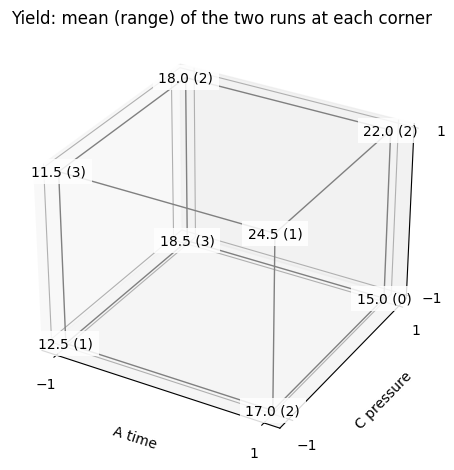

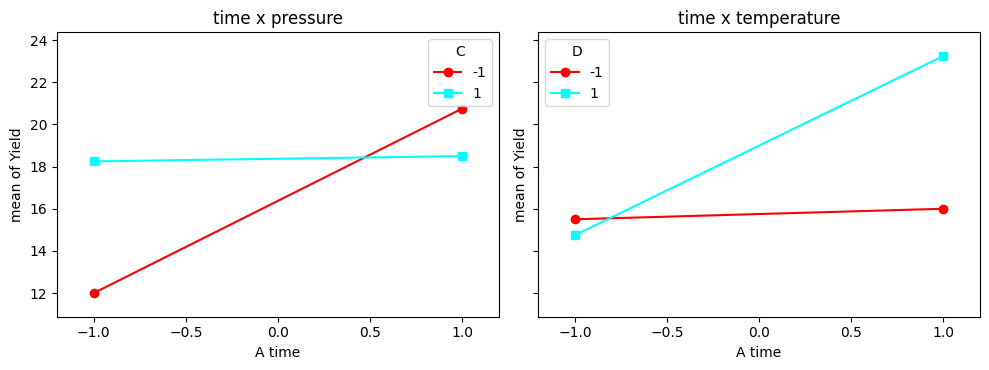

In [29]:
# (e) collapse into a 2^3 in A, C, D with two replicates: mean and range of the yield at each corner of the cube
cube = d628.groupby(["A", "C", "D"])["Yield"].agg(mean="mean", range=lambda s: s.max() - s.min(), runs=list).reset_index()
display(cube)

fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
for p, q in itertools.combinations(list(itertools.product([-1, 1], repeat=3)), 2):
    if sum(abs(a - b) for a, b in zip(p, q)) == 2:          # the 12 edges of the cube
        ax.plot(*zip(p, q), color="gray", lw=1)
for _, r in cube.iterrows():
    ax.text(r["A"], r["C"], r["D"], f"{r['mean']:.1f} ({r['range']:.0f})", ha="center", va="center", fontsize=10,
            bbox=dict(fc="white", ec="none", alpha=0.85))
ax.set(xlabel="A time", ylabel="C pressure", zlabel="D temperature", xticks=[-1, 1], yticks=[-1, 1], zticks=[-1, 1],
       title="Yield: mean (range) of the two runs at each corner")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
interaction_plot(d628["A"], d628["C"], d628["Yield"], ax=axes[0], markers=["o", "s"])
axes[0].set(title="time x pressure", xlabel="A time")
interaction_plot(d628["A"], d628["D"], d628["Yield"], ax=axes[1], markers=["o", "s"])
axes[1].set(title="time x temperature", xlabel="A time")
plt.tight_layout()
plt.show()

**(e)** Yes. $B$ and all its interactions are negligible, so the 16 runs are a $2^3$ in time, pressure and temperature with **two replicates**,
one at each concentration. The two yields at a corner differ by 0 to 3 lb (pure error $s = 1.4$), while the corner means differ by up to 13 lb.

Reading the cube: at short time (2.5 h) a higher pressure raises the yield from about 12 to 18 lb and the temperature does nothing.
At long time (3 h) a higher temperature raises the yield from about 16 to 23 lb and the high pressure costs about 2 lb.
This is what the interactions $AC$ and $AD$ mean: the right setting of pressure and temperature depends on the time.

**Conclusion.** The best corner is long time, low pressure, high temperature (3 h, 60 psi, 250 $^\circ$C): mean 24.5 lb (runs 25 and 24).
Concentration can be chosen for cost.

**Problem 6.29.** Use the regression model in part (c) of Problem 6.28 to generate a response surface contour plot of yield.
Discuss the practical value of this response surface plot.

**Solution:**

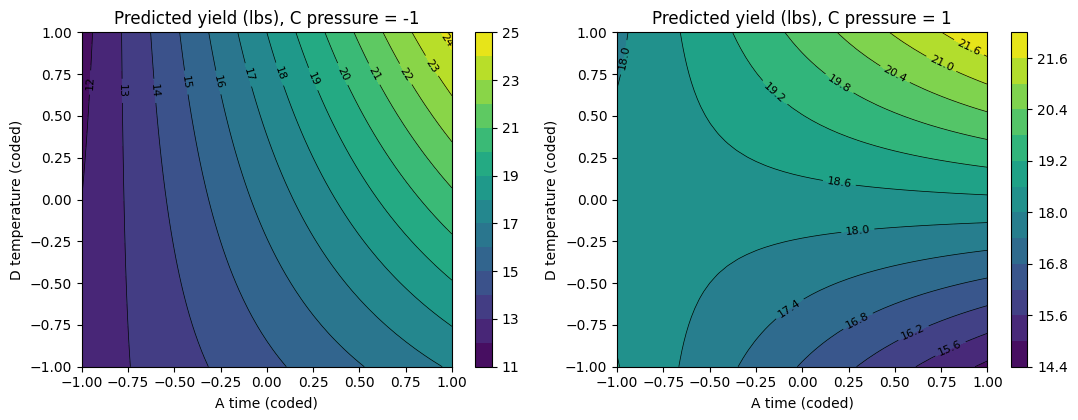

,A,C,D,predicted
5,1,-1,1,24.38
7,1,1,1,22.13
2,-1,1,-1,18.63
3,-1,1,1,17.88
4,1,-1,-1,17.13
6,1,1,-1,14.88
0,-1,-1,-1,12.38
1,-1,-1,1,11.63


In [30]:
g = np.linspace(-1, 1, 41)
X1, X4 = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, c in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": X1.ravel(), "C": c, "D": X4.ravel()})
    Z = m628.predict(grid).to_numpy().reshape(X1.shape)
    cs = ax.contourf(X1, X4, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(X1, X4, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A time (coded)", ylabel="D temperature (coded)", title=f"Predicted yield (lbs), C pressure = {c}")
plt.tight_layout()
plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = m628.predict(corners)
display(corners.sort_values("predicted", ascending=False).round(2))

**6.29.** The surface in time $\times$ temperature is twisted. At short time the contours are almost vertical: the temperature changes nothing.
At long time the yield rises steeply with the temperature. The right panel (high pressure) has the same shape, about 4 lb higher at short time
and 4 lb lower at long time: that is the $AC$ interaction. The highest predicted yield is $24.5$ lb at $x_1 = +1$, $x_3 = -1$, $x_4 = +1$
(3 h, 60 psi, 250 $^\circ$C).

**Practical value.** The plot shows at a glance where the yield is high, in which direction to move each variable, and how much one variable can be
traded for another (at 250 $^\circ$C the pressure hardly matters, at 2.5 h the temperature can be set at the cheaper level). Its limits: the
model is linear in each factor with interactions and was built from 16 runs at the corners of the box, so the contours are an interpolation and
must not be extended outside the box. They point to the direction for the next experiments (longer time, higher temperature), which should be
confirmed with new runs.

### Problems 6.31 and 6.32: a polymer (molecular weight and viscosity)

An experiment was conducted on a chemical process that produces a polymer. The four factors studied were temperature
($A$: 100 and 120 $^\circ$C), catalyst concentration ($B$: 4 and 8 %), time ($C$: 20 and 30 min) and pressure ($D$: 60 and
75 psi). Two responses, molecular weight and viscosity, were observed. The file `Problem_6_31.txt` contains the 16 runs of the
$2^4$ design in standard order followed by 4 center points.

**Use only the first 16 runs** (the factorial part). The center points and the test for curvature (part (b) of 6.31)
will come in Lecture 7.

In [31]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631 = p631.iloc[:16].copy()          # the 2^4 runs only
p631

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
0,100,4,20,60.0,2400,1400
1,120,4,20,60.0,2410,1500
2,100,8,20,60.0,2315,1520
3,120,8,20,60.0,2510,1630
4,100,4,30,60.0,2615,1380
5,120,4,30,60.0,2625,1525
6,100,8,30,60.0,2400,1500
7,120,8,30,60.0,2750,1620
8,100,4,20,75.0,2400,1400
9,120,4,20,75.0,2390,1525


**Problem 6.31**

(a) Consider only the molecular weight response. Plot the effect estimates on a normal probability scale. What effects
appear important?

(b) Use an analysis of variance to confirm the results from part (a).

(c) Write down a regression model to predict molecular weight as a function of the important variables.

(d) Analyze the residuals and comment on model adequacy.

(e) Repeat parts (a)-(d) using the viscosity response.

**Solution:**

**Coding.** $A$ temperature ($120\ ^\circ$C $= +1$), $B$ catalyst concentration ($8\ \% = +1$), $C$ time ($30$ min $= +1$),
$D$ pressure ($75$ psi $= +1$). Two responses: molecular weight and viscosity. Only the 16 factorial runs are used.

effects sorted by size:
term
C       201.25
A       123.75
AB      120.00
BC      -22.50
ABCD    -22.50
AC       20.00
ACD     -18.75
AD      -17.50
ABC      16.25
CD       12.50
B       -11.25
ABD     -11.25
BD        7.50
D         6.25
BCD       3.75


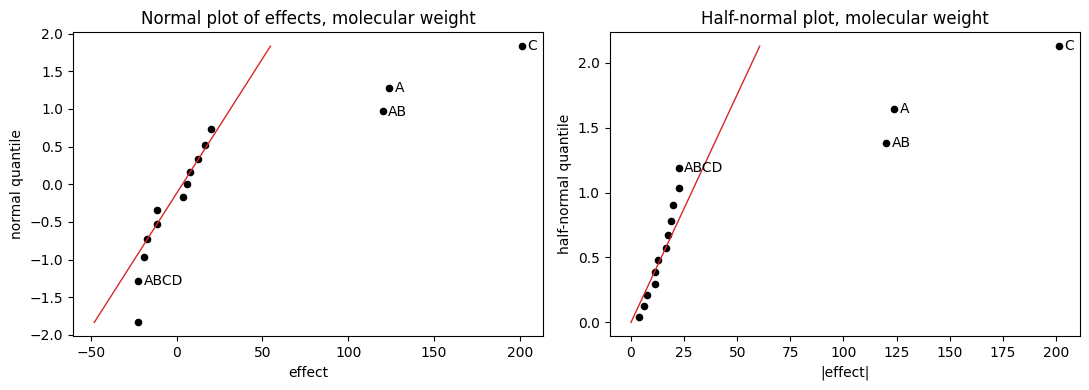

{'s0': np.float64(26.25), 'PSE': np.float64(21.56), 'ME': np.float64(55.43), 'SME': np.float64(112.53)}
|effect| > ME:  ['A', 'AB', 'C']
|effect| > SME: ['A', 'AB', 'C']


In [32]:
d631 = pd.DataFrame({"A": np.where(p631["Temperature"] == 120, 1, -1),
                     "B": np.where(p631["Concentration"] == 8, 1, -1),
                     "C": np.where(p631["Time"] == 30, 1, -1),
                     "D": np.where(p631["Pressure"] == 75, 1, -1),
                     "Weight": p631["Weight"], "Viscosity": p631["Viscosity"]})

# (a) molecular weight: effects, normal and half-normal plots, Lenth
tabW = effects_2k(d631, "Weight", list("ABCD"))
effW = tabW["effect"].rename(lambda t: t.replace(":", ""))
print("effects sorted by size:")
print(effW.reindex(effW.abs().sort_values(ascending=False).index).round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(effW, ax=axes[0], n_label=4, title="Normal plot of effects, molecular weight")
effect_plot(effW, half=True, ax=axes[1], n_label=4, title="Half-normal plot, molecular weight")
plt.tight_layout()
plt.show()
L = lenth(effW)
print({k: round(v, 2) for k, v in L.items()})
print("|effect| > ME: ", list(effW[effW.abs() > L["ME"]].index))
print("|effect| > SME:", list(effW[effW.abs() > L["SME"]].index))

**(a)** Three effects are far from the line: $C = 201$ (time), $A = 124$ (temperature) and $AB = 120$ (temperature $\times$ catalyst).
The other twelve are within $\pm 22.5$ and lie on the line, including $B = -11$ and everything with $D$ (pressure).
Lenth: $PSE = 21.6$, $ME = 55.4$, $SME = 112.5$; $A$, $AB$ and $C$ exceed even $SME$. Important: time, temperature and the temperature $\times$ catalyst
interaction. Tentative model $A$, $B$, $C$, $AB$ ($B$ is kept for hierarchy).

In [33]:
# (b) ANOVA, error pooled from the omitted effects; check with the projection into A, B, C
mW = smf.ols("Weight ~ A + B + C + A:B", data=d631).fit()
display(anova_lm(mW).round(4))
print(f"MS_E = {mW.mse_resid:.1f} with {mW.df_resid:.0f} df, s = {np.sqrt(mW.scale):.1f}, R2 = {mW.rsquared:.3f}, adj. R2 = {mW.rsquared_adj:.3f}")
print("\nProjection into A, B, C (D dropped, two replicates, pure error with 8 df):")
display(anova_lm(smf.ols("Weight ~ A * B * C", data=d631).fit()).round(4))
print("Mean molecular weight by temperature (columns) and catalyst (rows):")
display(d631.pivot_table(index="B", columns="A", values="Weight").round(1))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,61256.25,61256.2500,61.7828,0.0000
B,1.0,506.25,506.2500,0.5106,0.4898
C,1.0,162006.25,162006.2500,163.3989,0.0000
A:B,1.0,57600.00,57600.0000,58.0951,0.0000
Residual,11.0,10906.25,991.4773,NaN,NaN


MS_E = 991.5 with 11 df, s = 31.5, R2 = 0.963, adj. R2 = 0.949

Projection into A, B, C (D dropped, two replicates, pure error with 8 df):


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,61256.25,61256.250,78.7229,0.0000
B,1.0,506.25,506.250,0.6506,0.4432
A:B,1.0,57600.00,57600.000,74.0241,0.0000
C,1.0,162006.25,162006.250,208.2008,0.0000
A:C,1.0,1600.00,1600.000,2.0562,0.1895
B:C,1.0,2025.00,2025.000,2.6024,0.1454
A:B:C,1.0,1056.25,1056.250,1.3574,0.2775
Residual,8.0,6225.00,778.125,NaN,NaN


Mean molecular weight by temperature (columns) and catalyst (rows):


A,-1,1
B,,
-1,2510.0,2513.8
1,2378.8,2622.5


**(b) ANOVA.** $H_0$: the effect is zero, $F$-tests with $(1, 11)$ df, the error is pooled from the eleven omitted effects ($MS_E = 991$).
$C$: $F_0 = 163$, $P < 0.0001$. $A$: $F_0 = 61.8$, $P < 0.0001$. $AB$: $F_0 = 58.1$, $P < 0.0001$. All three **rejected**.
$B$: $F_0 = 0.5$, $P = 0.49$, not significant on its own. The projection into $A$, $B$, $C$ (pure error $MS_E = 778$ with 8 df) gives the same
answer and shows that $AC$, $BC$ and $ABC$ are not significant ($P \ge 0.15$). This confirms (a).

The interaction: at low catalyst (4 %) the temperature does nothing (2510 against 2514), at high catalyst (8 %) it adds 244 (2379 against 2622).

In [34]:
# (c) regression model
print(mW.params.round(3).to_string())

Intercept    2506.250
A              61.875
B              -5.625
C             100.625
A:B            60.000


**(c)** With $x_1$ temperature, $x_2$ catalyst, $x_3$ time:
$$\hat y_W = 2506 + 61.9\,x_1 - 5.6\,x_2 + 100.6\,x_3 + 60.0\,x_1 x_2, \qquad R^2 = 0.963,\ s = 31.$$

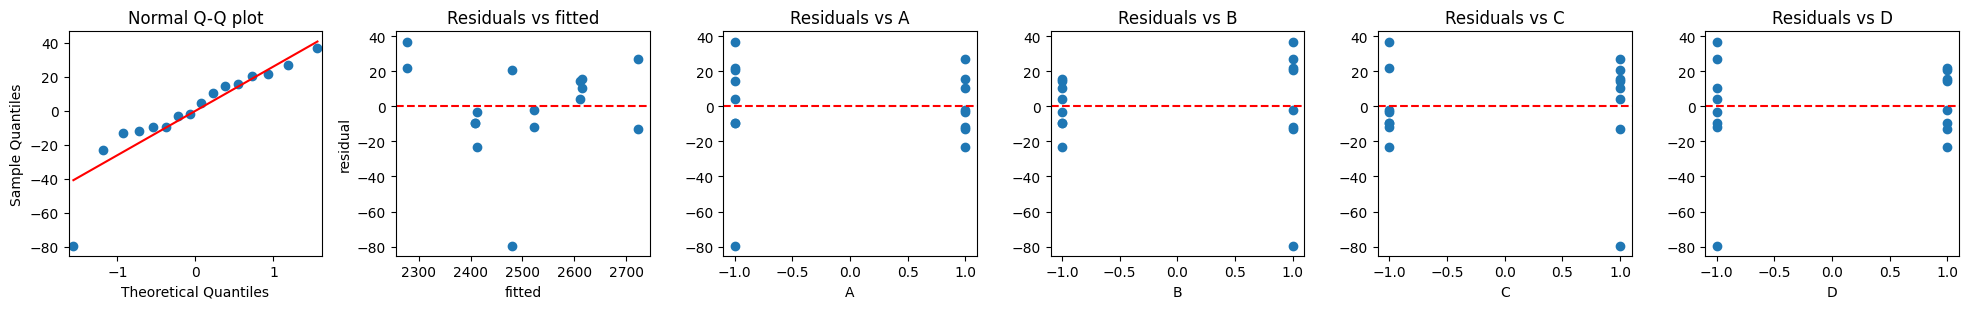

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8680678943976039), pvalue=np.float64(0.025409128758609296))


,A,B,C,D,Weight,Viscosity,fitted,std. residual
6,-1,1,1,-1,2400,1500,2479.4,-3.04
9,1,-1,-1,1,2390,1525,2413.1,-0.89
15,1,1,1,1,2710,1600,2723.1,-0.50


In [35]:
# (d) residuals, also against the dropped factor D
residual_plots(mW, d631, list("ABCD"))
stdW = pd.Series(mW.get_influence().resid_studentized_internal, index=d631.index, name="std. residual")
display(d631.join(mW.fittedvalues.rename("fitted").round(1)).join(stdW.round(2)).sort_values("std. residual").head(3))

**(d)** One run stands out: run 7 ($A = -1$, $B = +1$, $C = +1$, $D = -1$), weight 2400 against a fitted value of 2479, standardized residual
$-3.0$. It bends the Q-Q plot at the lower end (Shapiro-Wilk $p = 0.025$) and makes the spread at $C = +1$ look larger. The other 15 residuals are
within $\pm 1.4$ and show no pattern, also not against the dropped factor $D$. The model describes the main structure well ($R^2 = 0.96$),
but run 7 should be checked; a repeat of that run would tell whether it is a recording error.

effects sorted by size:
term
A       96.25
B       91.25
BD     -25.00
ABCD    23.75
AD     -22.50
BCD     18.75
D      -17.50
ABC     15.00
AB     -13.75
CD      13.75
AC      12.50
BC      10.00
ABD    -10.00
C        7.50
ACD     -1.25


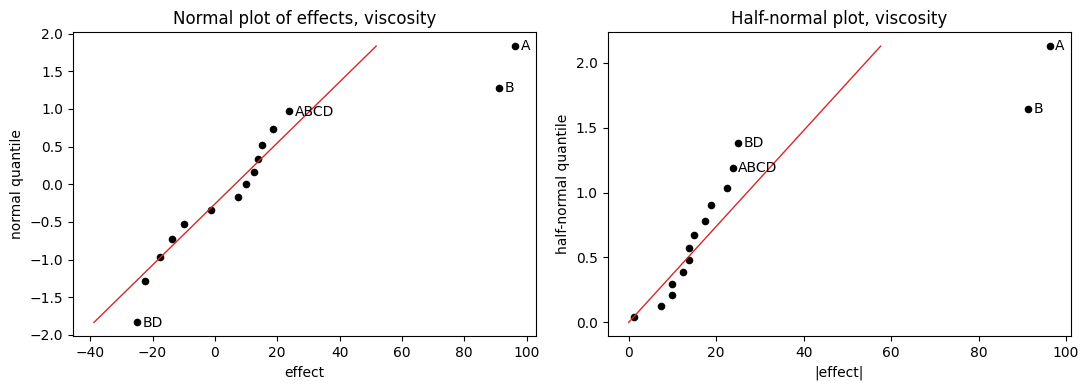

{'s0': np.float64(22.5), 'PSE': np.float64(20.62), 'ME': np.float64(53.02), 'SME': np.float64(107.63)}
|effect| > ME:  ['A', 'B']
|effect| > SME: []


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,37056.25,37056.2500,35.7334,0.0000
B,1.0,33306.25,33306.2500,32.1173,0.0001
Residual,13.0,13481.25,1037.0192,NaN,NaN


MS_E = 1037.0 with 13 df, s = 32.2, R2 = 0.839, adj. R2 = 0.814
Intercept    1500.625
A              48.125
B              45.625
is the interaction needed?  A:B in the model A*B:


,df,sum_sq,mean_sq,F,PR(>F)
A:B,1.0,756.25,756.2500,0.7132,0.4149
Residual,12.0,12725.00,1060.4167,NaN,NaN


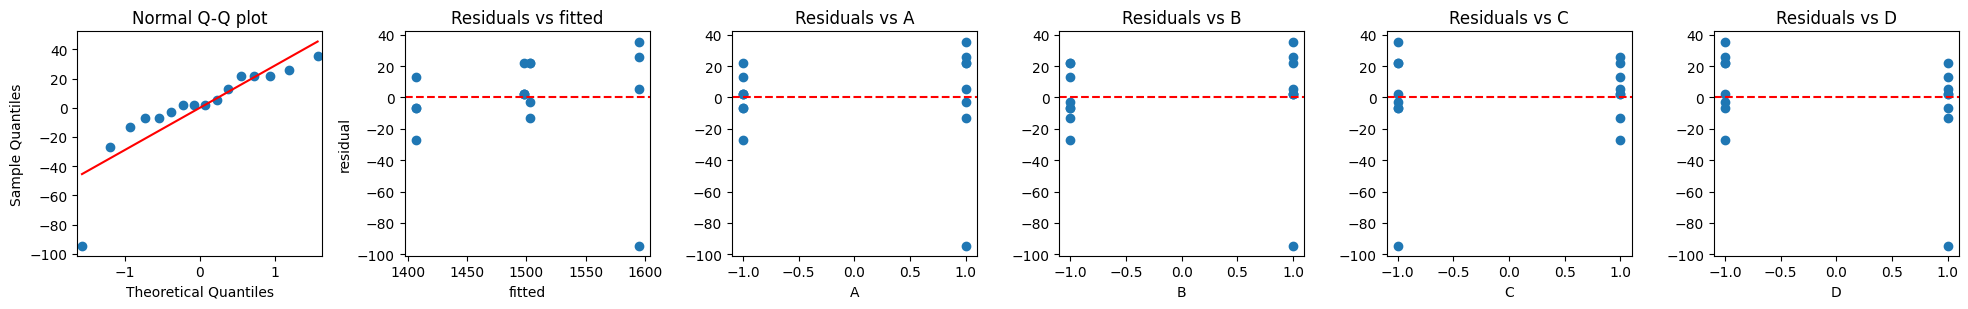

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.7933729462974546), pvalue=np.float64(0.002226960359650267))


,A,B,C,D,Weight,Viscosity,fitted,std. residual
11,1,1,-1,1,2520,1500,1594.4,-3.25
4,-1,-1,1,-1,2615,1380,1406.9,-0.93
13,1,-1,1,1,2630,1490,1503.1,-0.45


In [36]:
# (e) viscosity: effects, plots, Lenth
tabV = effects_2k(d631, "Viscosity", list("ABCD"))
effV = tabV["effect"].rename(lambda t: t.replace(":", ""))
print("effects sorted by size:")
print(effV.reindex(effV.abs().sort_values(ascending=False).index).round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(effV, ax=axes[0], n_label=4, title="Normal plot of effects, viscosity")
effect_plot(effV, half=True, ax=axes[1], n_label=4, title="Half-normal plot, viscosity")
plt.tight_layout()
plt.show()
L = lenth(effV)
print({k: round(v, 2) for k, v in L.items()})
print("|effect| > ME: ", list(effV[effV.abs() > L["ME"]].index))
print("|effect| > SME:", list(effV[effV.abs() > L["SME"]].index))

# ANOVA, regression and residuals of the model A + B
mV = smf.ols("Viscosity ~ A + B", data=d631).fit()
display(anova_lm(mV).round(4))
print(f"MS_E = {mV.mse_resid:.1f} with {mV.df_resid:.0f} df, s = {np.sqrt(mV.scale):.1f}, R2 = {mV.rsquared:.3f}, adj. R2 = {mV.rsquared_adj:.3f}")
print(mV.params.round(3).to_string())
print("is the interaction needed?  A:B in the model A*B:")
display(anova_lm(smf.ols("Viscosity ~ A * B", data=d631).fit()).round(4).loc[["A:B", "Residual"]])
residual_plots(mV, d631, list("ABCD"))
stdV = pd.Series(mV.get_influence().resid_studentized_internal, index=d631.index, name="std. residual")
display(d631.join(mV.fittedvalues.rename("fitted").round(1)).join(stdV.round(2)).sort_values("std. residual").head(3))

**(e) Viscosity.** $A = 96$ (temperature) and $B = 91$ (catalyst) are far from the line, the other thirteen effects are within $\pm 25$.
Lenth: $PSE = 20.6$, $ME = 53.0$, $SME = 107.6$; $A$ and $B$ exceed $ME$ but not the conservative $SME$. The gap between 91 and the next
effect (25) is clear, so the model is $A + B$; the interaction $AB = -14$ is noise ($F_0 = 0.7$, $P = 0.41$ when added).

ANOVA with $(1, 13)$ df: $A$: $F_0 = 35.7$, $P < 0.0001$; $B$: $F_0 = 32.1$, $P = 0.0001$, both **rejected**.
Regression: $\hat y_V = 1500.6 + 48.1\,x_1 + 45.6\,x_2$, $R^2 = 0.84$, $s = 32$.

Residuals: again one run, run 12 ($A = +1$, $B = +1$, $C = -1$, $D = +1$): viscosity 1500 where the fit is 1594 and the other three runs with
high temperature and high catalyst gave 1630, 1620 and 1600; standardized residual $-3.3$, Shapiro-Wilk $p = 0.002$. Apart from this run the
residuals are within $\pm 1.3$ with no pattern.

**Conclusion.** Molecular weight is driven by time, temperature and the temperature $\times$ catalyst interaction; viscosity rises with temperature
and with catalyst concentration (about $+96$ and $+91$ per step), time and pressure do not matter. Two single runs (7 for weight, 12 for viscosity)
are suspected outliers and should be checked.

**Problem 6.32.** Use the regression models for molecular weight and viscosity to answer the following questions.

(a) Construct a response surface contour plot for molecular weight. In what direction would you adjust the process variables
to increase molecular weight?

(b) Construct a response surface contour plot for viscosity. In what direction would you adjust the process variables to
decrease viscosity?

(c) What operating conditions would you recommend if it was necessary to produce a product with molecular weight between
2400 and 2500 and the lowest possible viscosity?

**Solution:**

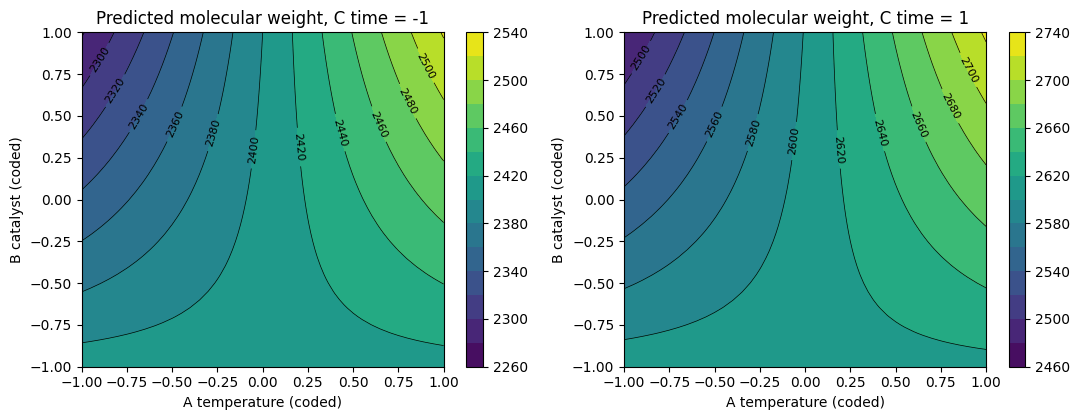

In [37]:
# (a) molecular weight in the temperature x catalyst plane at both times
g = np.linspace(-1, 1, 41)
X1, X2 = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, c in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": X1.ravel(), "B": X2.ravel(), "C": c})
    Z = mW.predict(grid).to_numpy().reshape(X1.shape)
    cs = ax.contourf(X1, X2, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(X1, X2, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature (coded)", ylabel="B catalyst (coded)", title=f"Predicted molecular weight, C time = {c}")
plt.tight_layout()
plt.show()

**(a)** Time shifts the whole surface up by 201 (left to right panel). Inside each panel the surface is twisted: at low catalyst the weight does
not depend on the temperature, at high catalyst it rises with the temperature; at low temperature more catalyst lowers the weight, at high
temperature it raises it. **To increase the molecular weight:** longer time, and high temperature together with high catalyst concentration
(corner $x_1 = x_2 = x_3 = +1$, predicted 2723, observed 2750 and 2710).

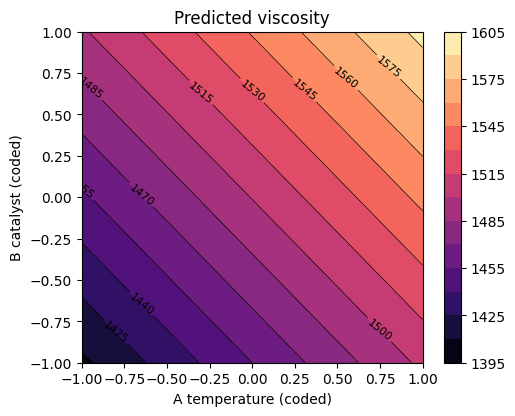

In [38]:
# (b) viscosity in the temperature x catalyst plane (time and pressure are not in the model)
fig, ax = plt.subplots(figsize=(5.5, 4.3))
grid = pd.DataFrame({"A": X1.ravel(), "B": X2.ravel()})
Z = mV.predict(grid).to_numpy().reshape(X1.shape)
cs = ax.contourf(X1, X2, Z, levels=12, cmap="magma")
ax.clabel(ax.contour(X1, X2, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
fig.colorbar(cs, ax=ax)
ax.set(xlabel="A temperature (coded)", ylabel="B catalyst (coded)", title="Predicted viscosity")
plt.show()

**(b)** Viscosity is a plane in temperature and catalyst: straight parallel contours running from the upper left to the lower right.
**To decrease the viscosity:** lower temperature and lower catalyst concentration; time and pressure can be chosen freely.

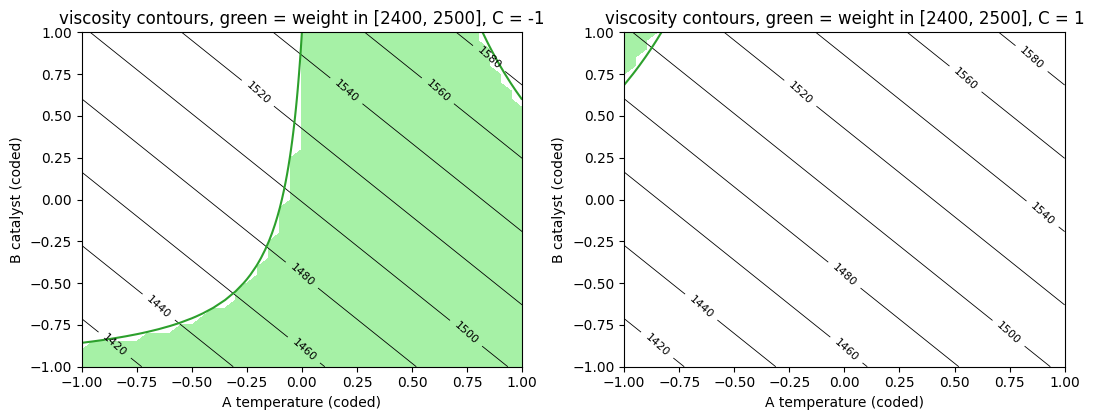

,A,B,C,Weight,Viscosity
0,-1.0,-1.0,-1.00,2409.38,1406.88
1,-1.0,-1.0,-0.95,2414.41,1406.88
2,-1.0,-1.0,-0.90,2419.44,1406.88
3,-1.0,-1.0,-0.85,2424.47,1406.88
4,-1.0,-1.0,-0.80,2429.50,1406.88
5,-1.0,-1.0,-0.75,2434.53,1406.88
6,-1.0,-1.0,-0.70,2439.56,1406.88
7,-1.0,-1.0,-0.65,2444.59,1406.88
8,-1.0,-1.0,-0.60,2449.63,1406.88
9,-1.0,-1.0,-0.55,2454.66,1406.88


time (min) = 25 + 5 * C, allowed C range at the best settings: -1.0 to -0.1


In [39]:
# (c) weight between 2400 and 2500 with the lowest viscosity
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, c in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": X1.ravel(), "B": X2.ravel(), "C": c})
    W = mW.predict(grid).to_numpy().reshape(X1.shape)
    V = mV.predict(grid[["A", "B"]]).to_numpy().reshape(X1.shape)
    ax.contourf(X1, X2, np.where((W >= 2400) & (W <= 2500), 1.0, np.nan), levels=[0.5, 1.5], colors="lightgreen", alpha=0.8)
    ax.clabel(ax.contour(X1, X2, V, levels=10, colors="k", linewidths=0.6), fontsize=8)
    ax.contour(X1, X2, W, levels=[2400, 2500], colors="tab:green", linewidths=1.5)
    ax.set(xlabel="A temperature (coded)", ylabel="B catalyst (coded)", title=f"viscosity contours, green = weight in [2400, 2500], C = {c}")
plt.tight_layout()
plt.show()

cube_grid = pd.DataFrame(list(itertools.product(g, g, g)), columns=["A", "B", "C"])
cube_grid["Weight"] = mW.predict(cube_grid)
cube_grid["Viscosity"] = mV.predict(cube_grid[["A", "B"]])
ok = cube_grid[(cube_grid["Weight"] >= 2400) & (cube_grid["Weight"] <= 2500)]
best = ok[ok["Viscosity"] == ok["Viscosity"].min()]
display(best.sort_values("C").round(2))
print("time (min) = 25 + 5 * C, allowed C range at the best settings:", best["C"].min().round(2), "to", best["C"].max().round(2))

**(c)** The lowest viscosity, about 1407, is at low temperature and low catalyst ($x_1 = x_2 = -1$); it does not depend on time.
There the weight is $2409 + 100.6\,(x_3 + 1)$, so it stays between 2400 and 2500 for $x_3$ from $-1$ to about $-0.1$,
that is a time of 20 to about 24 min.

**Recommendation:** temperature 100 $^\circ$C, catalyst 4 %, time about 22 min (predicted weight $\approx 2450$, in the middle of the band),
pressure at the cheaper level (it affects neither response). Predicted viscosity $\approx 1407$. The two runs at this corner with 20 min gave
weights 2400, 2400 and viscosities 1400, 1400, which agrees with the model. Since 20 min is at the edge of the band, a confirmation run at
about 22 min is advisable.

### Problem 6.36: resistivity of a silicon wafer

Resistivity on a silicon wafer is influenced by several factors. The results of a single replicate of a $2^4$ factorial
experiment performed during a critical processing step are (standard order):

In [40]:
p636 = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=list("ABCD"))
p636["resistivity"] = [1.92, 11.28, 1.09, 5.75, 2.13, 9.53, 1.03, 5.35,
                       1.60, 11.73, 1.16, 4.68, 2.16, 9.11, 1.07, 5.30]
p636

,A,B,C,D,resistivity
0,-1,-1,-1,-1,1.92
1,1,-1,-1,-1,11.28
2,-1,1,-1,-1,1.09
3,1,1,-1,-1,5.75
4,-1,-1,1,-1,2.13
5,1,-1,1,-1,9.53
6,-1,1,1,-1,1.03
7,1,1,1,-1,5.35
8,-1,-1,-1,1,1.60
9,1,-1,-1,1,11.73


**Problem 6.36**

(a) Estimate the factor effects. Plot the effect estimates on a normal probability plot and select a tentative model.

(b) Fit the model identified in part (a) and analyze the residuals. Is there any indication of model inadequacy?

(c) Repeat the analysis from parts (a) and (b) using $\ln(y)$ as the response variable. Is there an indication that the
transformation has been useful?

(d) Fit a model in terms of the coded variables that can be used to predict the resistivity.

**Solution:**

effects sorted by size:
term
A       6.321
B      -3.004
AB     -2.139
ABC     0.689
AC     -0.596
BC      0.459
C      -0.441
ABCD    0.284
ABD    -0.194
BCD     0.189
D      -0.159
AD     -0.114
BD     -0.094
CD      0.059
ACD    -0.021


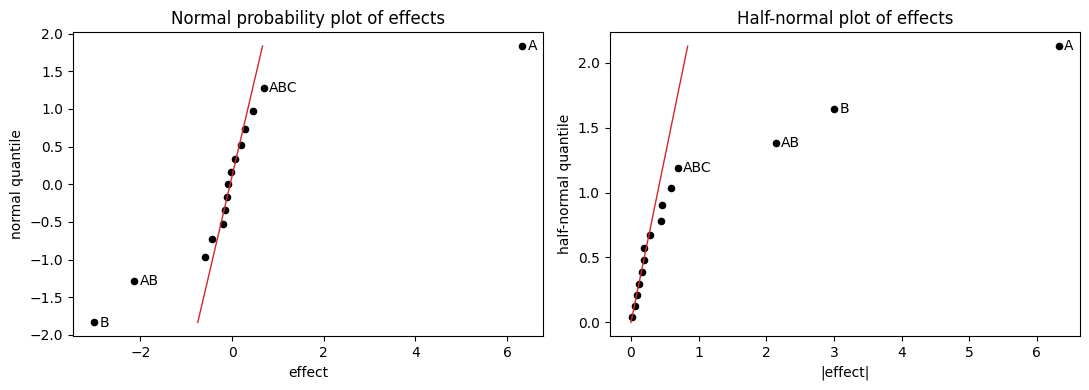

{'s0': np.float64(0.426), 'PSE': np.float64(0.287), 'ME': np.float64(0.737), 'SME': np.float64(1.497)}
|effect| > ME:  ['A', 'B', 'AB']
|effect| > SME: ['A', 'B', 'AB']


In [41]:
# (a) effects of the resistivity, normal and half-normal plots, Lenth
tab636 = effects_2k(p636, "resistivity", list("ABCD"))
eff636 = tab636["effect"].rename(lambda t: t.replace(":", ""))
print("effects sorted by size:")
print(eff636.reindex(eff636.abs().sort_values(ascending=False).index).round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff636, ax=axes[0], n_label=4)
effect_plot(eff636, half=True, ax=axes[1], n_label=4)
plt.tight_layout()
plt.show()
L = lenth(eff636)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff636[eff636.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff636[eff636.abs() > L["SME"]].index))

**(a)** $A = 6.32$, $B = -3.00$ and $AB = -2.14$ are far from the line, the other twelve effects are within $\pm 0.7$.
Lenth: $PSE = 0.29$, $ME = 0.74$, $SME = 1.50$; the same three exceed $SME$ ($ABC = 0.69$ stays below $ME$).
**Tentative model:** $A$, $B$, $AB$.

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,159.8328,159.8328,333.0877,0.0
B,1.0,36.0901,36.0901,75.2108,0.0
A:B,1.0,18.2970,18.2970,38.1305,0.0
Residual,12.0,5.7582,0.4799,NaN,NaN


Intercept    4.681
A            3.161
B           -1.502
A:B         -1.069 
R2 = 0.974, s = 0.693


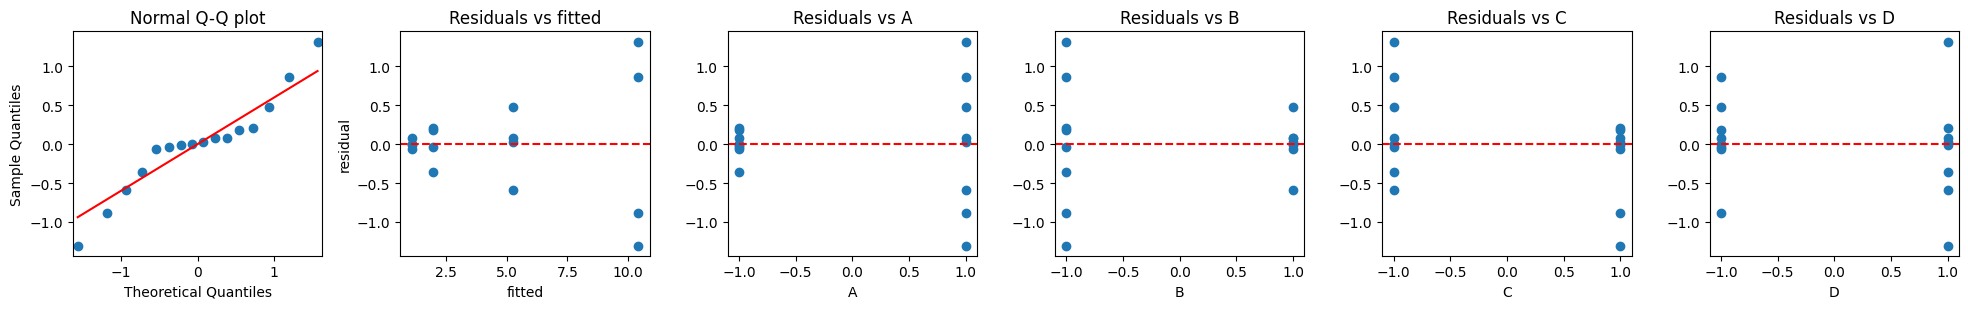

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9428466534821184), pvalue=np.float64(0.38535699262395734))
spread of the residuals at each fitted value (= cell mean of A x B):
          min    max    std
fitted                     
1.09   -0.058  0.072  0.054
1.95   -0.353  0.207  0.258
5.27   -0.590  0.480  0.442
10.41  -1.303  1.317  1.286


In [42]:
# (b) fit A + B + AB and look at the residuals
m636 = smf.ols("resistivity ~ A + B + A:B", data=p636).fit()
display(anova_lm(m636).round(4))
print(m636.params.round(3).to_string(), f"\nR2 = {m636.rsquared:.3f}, s = {np.sqrt(m636.scale):.3f}")
residual_plots(m636, p636, list("ABCD"))
print("spread of the residuals at each fitted value (= cell mean of A x B):")
print(pd.DataFrame({"fitted": m636.fittedvalues.round(2), "resid": m636.resid}).groupby("fitted")["resid"].agg(["min", "max", "std"]).round(3))

**(b)** ANOVA with $(1, 12)$ df: $A$: $F_0 = 333$, $B$: $F_0 = 75$, $AB$: $F_0 = 38$, all $P < 0.0001$, rejected. $R^2 = 0.974$.
But the residuals form a clear **funnel**: at the fitted value 1.09 they are within $\pm 0.07$, at 1.95 within $\pm 0.35$, at 5.27 within
$\pm 0.6$ and at 10.4 within $\pm 1.3$. The spread grows with the mean (standard deviation from 0.05 to 1.1, a factor of 20).
Shapiro-Wilk ($p = 0.39$) does not see this, the plot does. The constant-variance assumption fails, so the $F$-tests and the model are not
reliable as they stand. A spread proportional to the mean together with an interaction between two strong factors points to multiplicative
effects: try $\ln y$.

effects sorted by size:
term
A       1.626
B      -0.629
ABC     0.127
AC     -0.079
ABCD    0.063
ABD    -0.060
AB     -0.049
D      -0.036
CD      0.036
AD     -0.019
C      -0.013
BC     -0.008
BCD     0.008
ACD    -0.007
BD      0.007


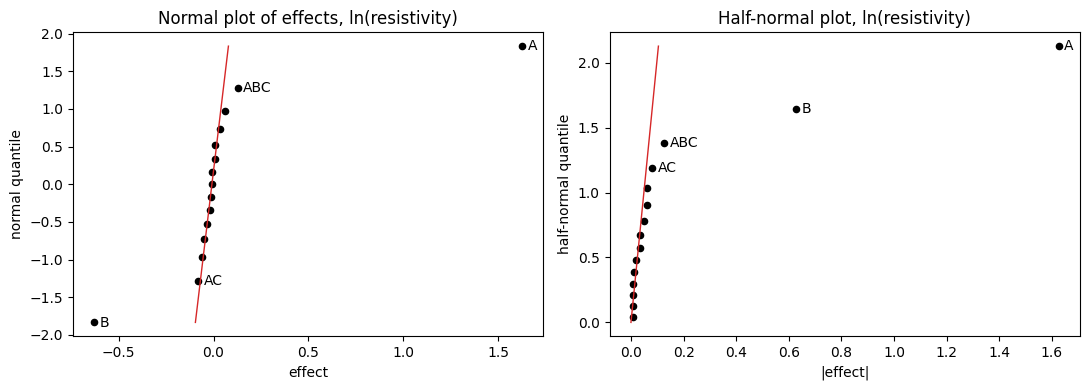

{'s0': np.float64(0.054), 'PSE': np.float64(0.053), 'ME': np.float64(0.137), 'SME': np.float64(0.278)}
|effect| > ME:  ['A', 'B']
|effect| > SME: ['A', 'B']


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,10.5721,10.5721,962.9454,0.0
B,1.0,1.5803,1.5803,143.9414,0.0
Residual,13.0,0.1427,0.0110,NaN,NaN


R2 = 0.988, s = 0.105
is the interaction still needed?  A:B in the model A*B:


,df,sum_sq,mean_sq,F,PR(>F)
A:B,1.0,0.0097,0.0097,0.8798,0.3668
Residual,12.0,0.1330,0.0111,NaN,NaN


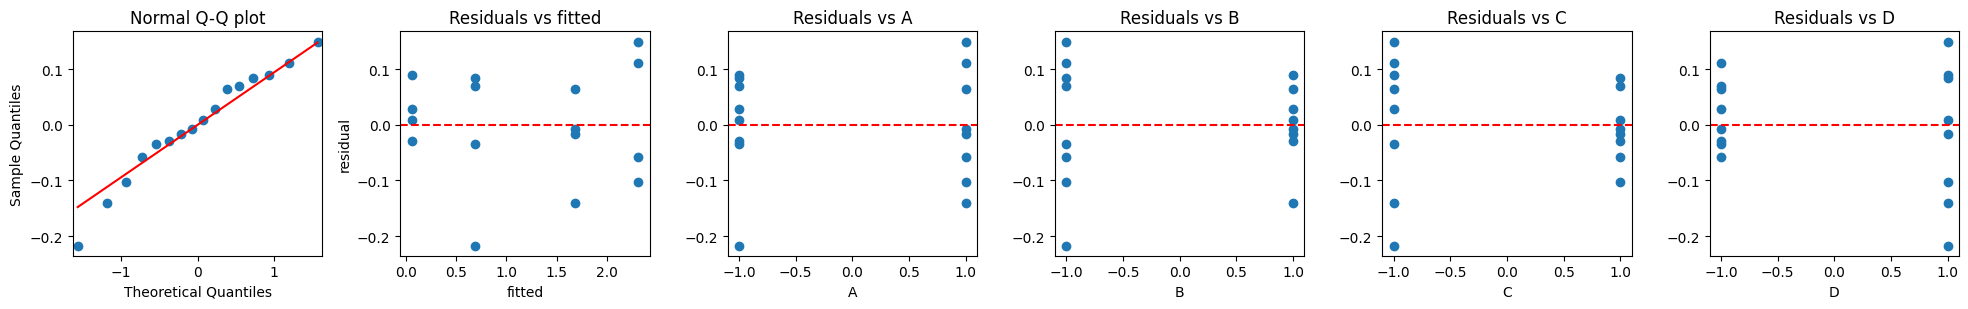

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9667947125870833), pvalue=np.float64(0.7843979538937538))
spread of the residuals at each fitted value:
          min    max    std
fitted                     
0.06   -0.029  0.090  0.050
0.69   -0.217  0.083  0.138
1.68   -0.141  0.065  0.085
2.31   -0.103  0.150  0.124


In [43]:
# (c) the same analysis for ln(resistivity)
p636["ln_y"] = np.log(p636["resistivity"])
tab_ln = effects_2k(p636, "ln_y", list("ABCD"))
eff_ln = tab_ln["effect"].rename(lambda t: t.replace(":", ""))
print("effects sorted by size:")
print(eff_ln.reindex(eff_ln.abs().sort_values(ascending=False).index).round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff_ln, ax=axes[0], n_label=4, title="Normal plot of effects, ln(resistivity)")
effect_plot(eff_ln, half=True, ax=axes[1], n_label=4, title="Half-normal plot, ln(resistivity)")
plt.tight_layout()
plt.show()
L = lenth(eff_ln)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff_ln[eff_ln.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff_ln[eff_ln.abs() > L["SME"]].index))

m_ln = smf.ols("ln_y ~ A + B", data=p636).fit()
display(anova_lm(m_ln).round(4))
print(f"R2 = {m_ln.rsquared:.3f}, s = {np.sqrt(m_ln.scale):.3f}")
print("is the interaction still needed?  A:B in the model A*B:")
display(anova_lm(smf.ols("ln_y ~ A * B", data=p636).fit()).round(4).loc[["A:B", "Residual"]])
residual_plots(m_ln, p636, list("ABCD"))
print("spread of the residuals at each fitted value:")
print(pd.DataFrame({"fitted": m_ln.fittedvalues.round(2), "resid": m_ln.resid}).groupby("fitted")["resid"].agg(["min", "max", "std"]).round(3))

**(c)** On the log scale only two effects are active: $A = 1.63$ and $B = -0.63$ ($PSE = 0.053$, $ME = 0.14$, $SME = 0.28$).
The interaction has disappeared ($AB = -0.05$; added to the model, $F_0 = 0.9$, $P = 0.37$) and $ABC = 0.13$ is below $ME$.
Model $\ln y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \varepsilon$, $F$-tests with $(1, 13)$ df: $A$: $F_0 = 963$, $B$: $F_0 = 144$,
both $P < 0.0001$, rejected. $R^2 = 0.988$. The residuals now have the same spread at all four fitted values (standard deviations 0.04 to 0.14,
no trend), the Q-Q plot is close to a line, Shapiro-Wilk $p = 0.78$.

**The transformation was useful:** a simpler model (two main effects instead of two main effects plus an interaction), constant variance and a
better fit. The interaction on the original scale was only the multiplicative structure seen on an additive scale.

In [44]:
# (d) prediction model in coded variables and back-transformation
print(m_ln.params.round(4).to_string())
pred = pd.DataFrame({"A": [-1, 1, -1, 1], "B": [-1, -1, 1, 1]})
pred["predicted ln y"] = m_ln.predict(pred)
pred["predicted resistivity"] = np.exp(pred["predicted ln y"])
pred = pred.merge(p636.groupby(["A", "B"])["resistivity"].mean().rename("observed mean").reset_index(), on=["A", "B"])
display(pred.round(3))

Intercept    1.1854
A            0.8129
B           -0.3143


,A,B,predicted ln y,predicted resistivity,observed mean
0,-1,-1,0.687,1.987,1.953
1,1,-1,2.313,10.100,10.412
2,-1,1,0.058,1.060,1.088
3,1,1,1.684,5.387,5.270


**(d)** $\widehat{\ln y} = 1.185 + 0.813\,x_1 - 0.314\,x_2$, that is
$$\hat y = e^{1.185}\, e^{0.813\,x_1}\, e^{-0.314\,x_2} = 3.27 \cdot 2.26^{\,x_1} \cdot 0.73^{\,x_2}.$$
Going from the low to the high level of $A$ multiplies the resistivity by $e^{1.63} = 5.1$, the high level of $B$ multiplies it by
$e^{-0.63} = 0.53$. The factors act multiplicatively, which is why the additive model needed an interaction. Predictions at the four
combinations of $A$ and $B$: 1.99, 10.10, 1.06, 5.39 against the observed means 1.95, 10.41, 1.09, 5.27 ($e^{\widehat{\ln y}}$ estimates the
median of the resistivity, not its mean). $C$ and $D$ do not enter and can be set at the cheapest level.

**Conclusion.** Resistivity is governed by $A$ (factor 5) and $B$ (factor 0.5) on a multiplicative scale; the log model with two main effects
predicts it well and has well-behaved residuals.

### Problem 6.30 (optional): the scrumptious brownie experiment

The purpose of this experiment was to determine how the pan material ($A$: glass, aluminum), the stirring method
($B$: spoon, mixer) and the brand of brownie mix ($C$: expensive, cheap) affect the scrumptiousness of brownies, a subjective
measure from a questionnaire (taste, appearance, consistency, aroma, ...). An eight-person test panel sampled each batch and
filled out the questionnaire. Each row below is **one batch** of brownies; the 8 columns are the ratings of the 8 panel members.

In [45]:
brownie = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=3)], columns=list("ABC"))
ratings = [[11, 9, 10, 10, 11, 10, 8, 9],
           [15, 10, 16, 14, 12, 9, 6, 15],
           [9, 12, 11, 11, 11, 11, 11, 12],
           [16, 17, 15, 12, 13, 13, 11, 11],
           [10, 11, 15, 8, 6, 8, 9, 14],
           [12, 13, 14, 13, 9, 13, 14, 9],
           [10, 12, 13, 10, 7, 7, 17, 13],
           [15, 12, 15, 13, 12, 12, 9, 14]]
brownie = brownie.join(pd.DataFrame(ratings, columns=[f"taster{i}" for i in range(1, 9)]))
brownie

,A,B,C,taster1,taster2,taster3,taster4,taster5,taster6,taster7,taster8
0,-1,-1,-1,11,9,10,10,11,10,8,9
1,1,-1,-1,15,10,16,14,12,9,6,15
2,-1,1,-1,9,12,11,11,11,11,11,12
3,1,1,-1,16,17,15,12,13,13,11,11
4,-1,-1,1,10,11,15,8,6,8,9,14
5,1,-1,1,12,13,14,13,9,13,14,9
6,-1,1,1,10,12,13,10,7,7,17,13
7,1,1,1,15,12,15,13,12,12,9,14


**Problem 6.30 (optional)**

(a) Analyze the data from this experiment as if there were eight replicates of a $2^3$ design. Comment on the results.

(b) Is the analysis in part (a) the correct approach? There are only eight batches; do we really have eight replicates of a
$2^3$ factorial design?

(c) Analyze the average and standard deviation of the scrumptiousness ratings. Comment on the results. Is this analysis more
appropriate than the one in part (a)? Why or why not?

**Solution:**

In [46]:
# (a) the 64 ratings as 8 replicates of a 2^3 design
tasters = [f"taster{i}" for i in range(1, 9)]
long = brownie.melt(id_vars=list("ABC"), value_vars=tasters, var_name="taster", value_name="rating")
m_long = smf.ols("rating ~ A * B * C", data=long).fit()
display(anova_lm(m_long).round(4))
print("effects (2 x coefficients):")
print((2 * m_long.params.drop("Intercept")).round(3).to_string())

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,72.2500,72.2500,11.9527,0.0010
B,1.0,18.0625,18.0625,2.9882,0.0894
A:B,1.0,0.0625,0.0625,0.0103,0.9194
C,1.0,0.0625,0.0625,0.0103,0.9194
A:C,1.0,1.5625,1.5625,0.2585,0.6132
B:C,1.0,1.0000,1.0000,0.1654,0.6858
A:B:C,1.0,0.2500,0.2500,0.0414,0.8396
Residual,56.0,338.5000,6.0446,NaN,NaN


effects (2 x coefficients):
A        2.125
B        1.062
A:B     -0.062
C       -0.062
A:C     -0.313
B:C     -0.250
A:B:C   -0.125


**(a)** Treating the 64 ratings as 8 replicates: error with 56 df, $MS_E = 6.04$. Pan material $A$: $F_0 = 12.0$, $P = 0.001$
(aluminum $+2.1$ points); stirring $B$: $F_0 = 3.0$, $P = 0.09$ (mixer $+1.1$); brand $C$ and all interactions: nothing.
Read this way, the aluminum pan is better, the mixer perhaps, the brand does not matter.

**(b)** No, this is not the correct approach. The treatment (pan, stirring, mix) was applied to a **batch**, and there are only 8 batches,
one per combination. The 8 tasters rate the same batch, so their ratings are 8 measurements of one experimental unit, not 8 independent
repetitions of the treatment. Anything that happened to that batch (oven, mixing, baking time) is shared by all 8 ratings, so they are
correlated. The analysis in (a) uses 56 error df from taster disagreement, while the true replication of the treatment is zero: it is an
unreplicated $2^3$, and the error in (a) measures the wrong thing (taster-to-taster instead of batch-to-batch variation). Its $F$-tests are too
optimistic.

,A,B,C,mean,sd
0,-1,-1,-1,9.75,1.04
1,1,-1,-1,12.12,3.52
2,-1,1,-1,11.00,0.93
3,1,1,-1,13.50,2.27
4,-1,-1,1,10.12,3.09
5,1,-1,1,12.12,2.03
6,-1,1,1,11.12,3.36
7,1,1,1,12.75,1.98


mean: effects {'A': 2.125, 'B': 1.062, 'AB': -0.062, 'C': -0.062, 'AC': -0.312, 'BC': -0.25, 'ABC': -0.125}
      Lenth: PSE = 0.188, ME = 0.706, SME = 1.689;  adjusted limits (m = 7): ME = 0.430, SME = 0.917
sd: effects {'A': 0.349, 'B': -0.287, 'AB': -0.365, 'C': 0.677, 'AC': -1.566, 'BC': 0.395, 'ABC': 0.208}
      Lenth: PSE = 0.535, ME = 2.016, SME = 4.824;  adjusted limits (m = 7): ME = 1.229, SME = 2.619


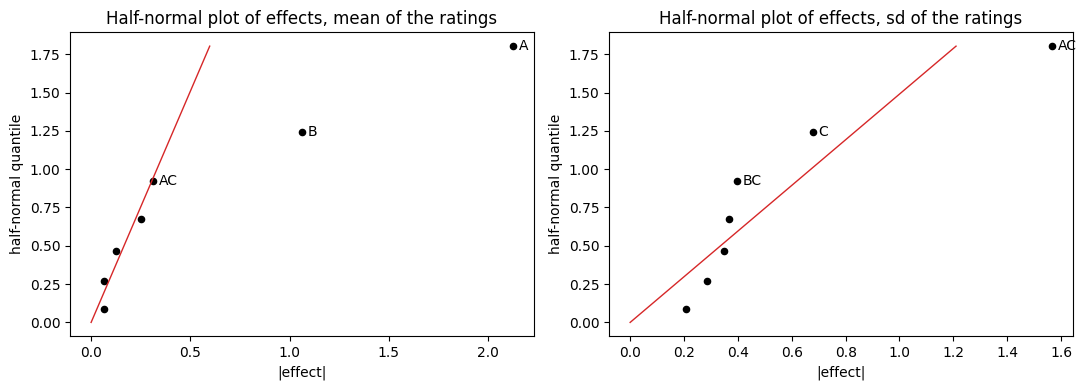

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,9.0313,9.0313,122.9787,0.0001
B,1.0,2.2578,2.2578,30.7447,0.0026
Residual,5.0,0.3672,0.0734,NaN,NaN


Intercept    11.562
A             1.063
B             0.531 
R2 = 0.968


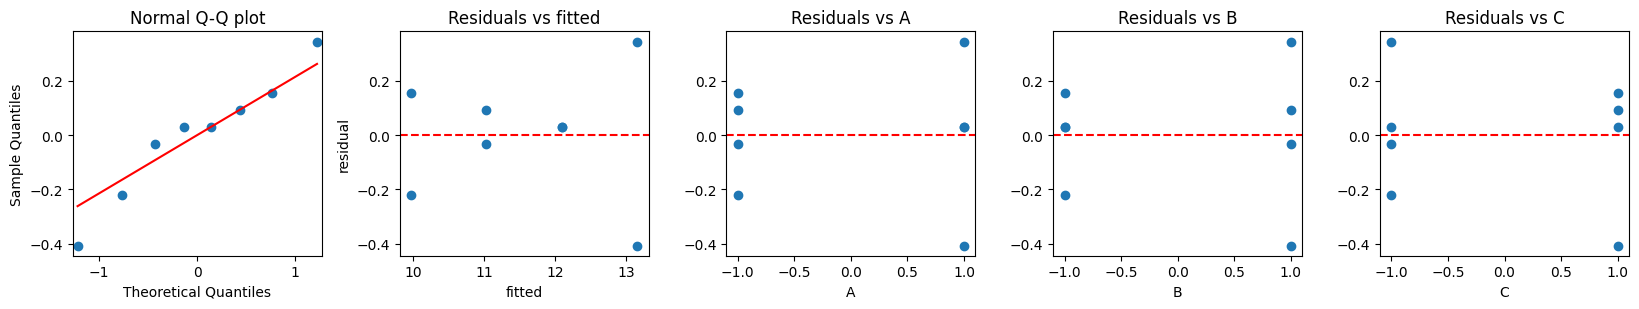

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9618791380049735), pvalue=np.float64(0.8277995977947945))


In [47]:
# (c) one number per batch: mean and standard deviation of the 8 ratings, each analysed as an unreplicated 2^3
brownie["mean"] = brownie[tasters].mean(axis=1)
brownie["sd"] = brownie[tasters].std(axis=1)
display(brownie[list("ABC") + ["mean", "sd"]].round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, resp in zip(axes, ["mean", "sd"]):
    e = effects_2k(brownie, resp, list("ABC"))["effect"].rename(lambda t: t.replace(":", ""))
    L = lenth(e)
    print(f"{resp}: effects", e.round(3).to_dict())
    print(f"      Lenth: PSE = {L['PSE']:.3f}, ME = {L['ME']:.3f}, SME = {L['SME']:.3f};  adjusted limits (m = 7): ME = {2.295 * L['PSE']:.3f}, SME = {4.891 * L['PSE']:.3f}")
    effect_plot(e, half=True, ax=ax, n_label=3, title=f"Half-normal plot of effects, {resp} of the ratings")
plt.tight_layout()
plt.show()

m_mean = smf.ols("mean ~ A + B", data=brownie).fit()
display(anova_lm(m_mean).round(4))
print(m_mean.params.round(3).to_string(), f"\nR2 = {m_mean.rsquared:.3f}")
residual_plots(m_mean, brownie, list("ABC"))

**(c) Mean rating** (one number per batch, an unreplicated $2^3$ with 7 effects, so the half-normal plot is the better one): $A = 2.1$ and
$B = 1.1$ stand apart, the other five effects are within $\pm 0.3$. Lenth with $m = 7$: $PSE = 0.19$, $ME = 0.71$, $SME = 1.69$
(adjusted limits 0.43 and 0.92); $A$ and $B$ exceed $ME$. Model mean $\sim A + B$ with the five omitted effects as the error (5 df):
$A$: $F_0 = 123$, $P = 0.0001$; $B$: $F_0 = 31$, $P = 0.003$, both rejected. Same conclusion as (a), aluminum pan $+2.1$ and mixer $+1.1$ points,
but now with the correct experimental unit and only 5 error df. The residuals (5 df) show nothing unusual.

**Standard deviation** (how much the panel disagrees): $AC = -1.57$ is apart from the rest in the half-normal plot, $C = 0.68$ comes next.
It exceeds only the adjusted $ME$ (1.23), not the original one (2.02); with 7 effects and $d = 2.3$ df this is weak evidence. If real, the panel
agrees best on the glass pan with the expensive mix (sd about 1) and on aluminum with the cheap mix (sd about 2), and disagrees most on the other
two combinations (sd 2.3 to 3.5).

**Is (c) more appropriate?** Yes. The experimental unit is the batch, so the analysis must use one summary per batch. The mean answers
"which brownies are better on average", the standard deviation answers "which brownies divide the panel", which (a) cannot see at all.
The price is that there are only 8 numbers and the error comes from the omitted effects, so the tests are less sensitive; that is the true
information content of 8 batches.